<table> <tr> <th>Expert\Token</th> <th>1</th> <th>2</th> <th>3</th> <th>4</th> </tr> <tr> <td>8</td> <td>0.0027</td> <td>0.0026</td> <td>0.0026</td> <td>0.0022</td> </tr> <tr> <td>16</td> <td>0.0028</td> <td>0.0027</td> <td>0.0027</td> <td>0.0023</td> </tr> <tr> <td>32</td> <td>0.0025</td> <td>0.0024</td> <td>0.0024</td> <td>0.0020</td> </tr> <tr> <td>64</td> <td>0.0029</td> <td>0.0028</td> <td>0.0028</td> <td>0.0024</td> </tr> <tr> <td>128</td> <td>0.0029</td> <td>0.0028</td> <td>0.0028</td> <td>0.0024</td> </tr> </table>

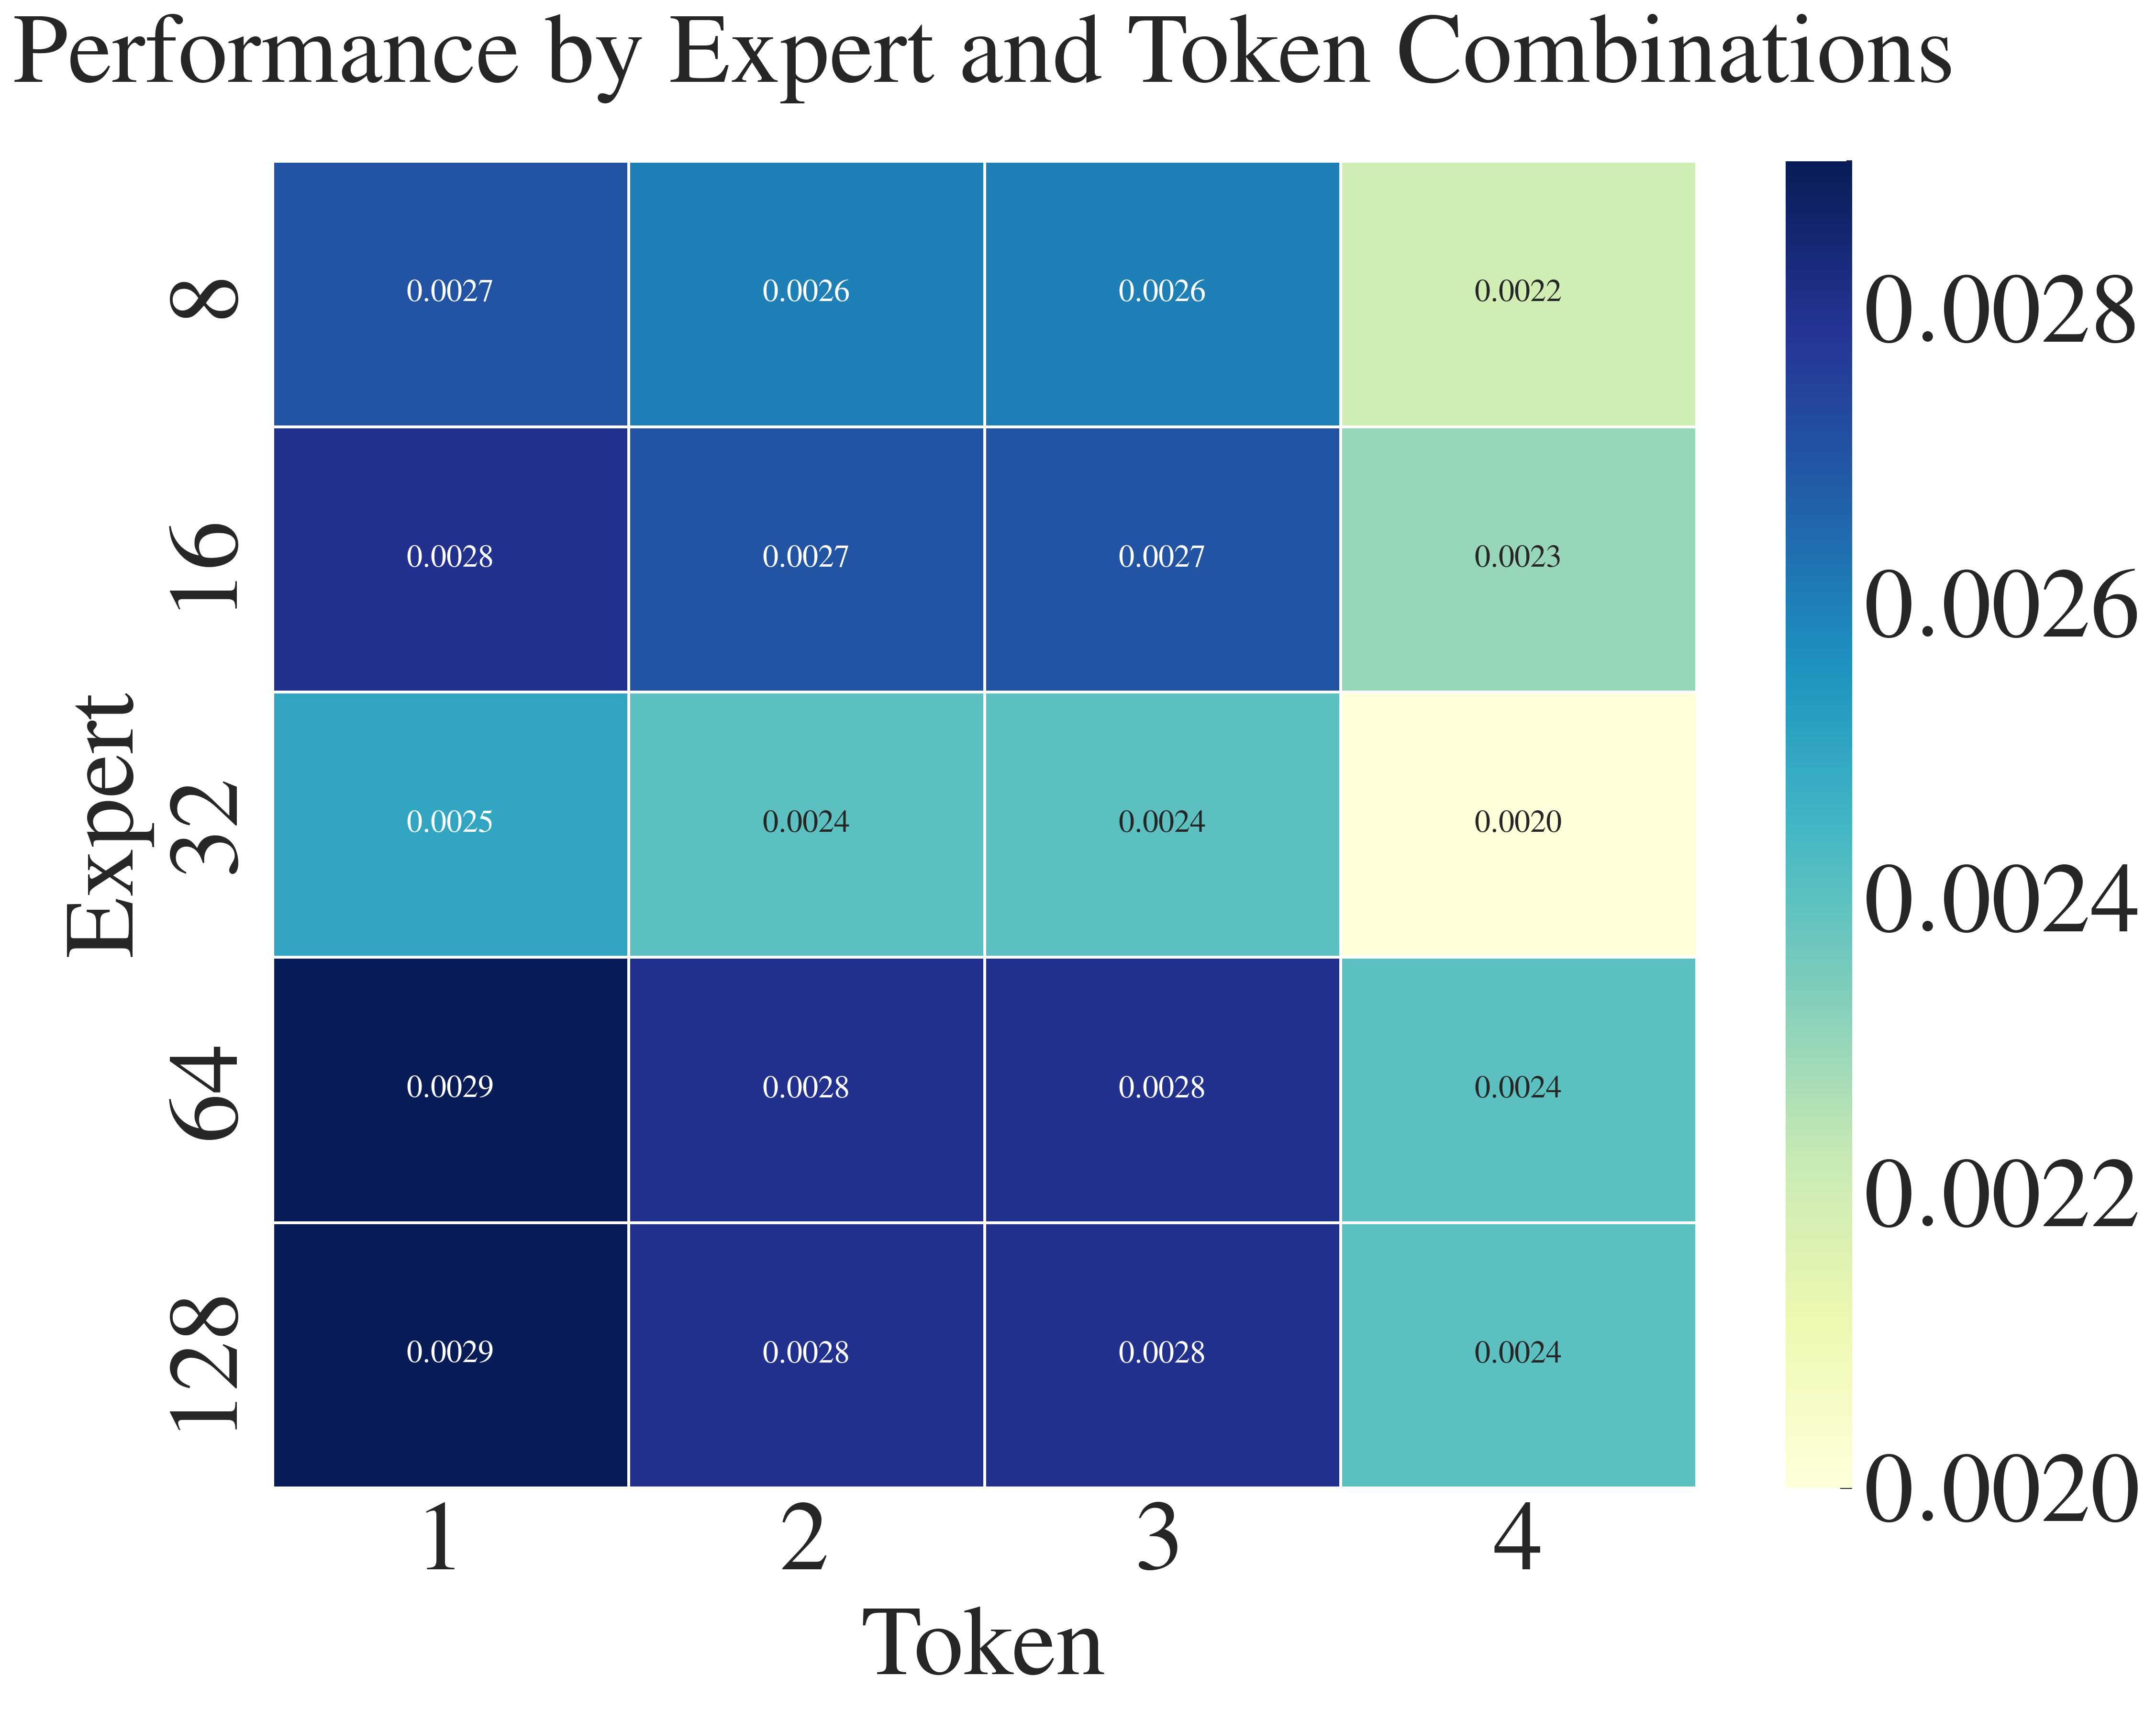

In [52]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 创建数据框
data = {
    'Expert': ['8', '16', '32', '64', '128'],
    '1': [0.0027, 0.0028, 0.0025, 0.0029, 0.0029],
    '2': [0.0026, 0.0027, 0.0024, 0.0028, 0.0028],
    '3': [0.0026, 0.0027, 0.0024, 0.0028, 0.0028],
    '4': [0.0022, 0.0023, 0.0020, 0.0024, 0.0024]
}
df = pd.DataFrame(data).set_index('Expert')

# 绘制热力图
plt.figure(figsize=(8, 6))
sns.heatmap(df, annot=True, fmt=".4f", cmap="YlGnBu", linewidths=0.5)
plt.title("Performance by Expert and Token Combinations", pad=20)
plt.xlabel("Token")
plt.ylabel("Expert")
plt.show()

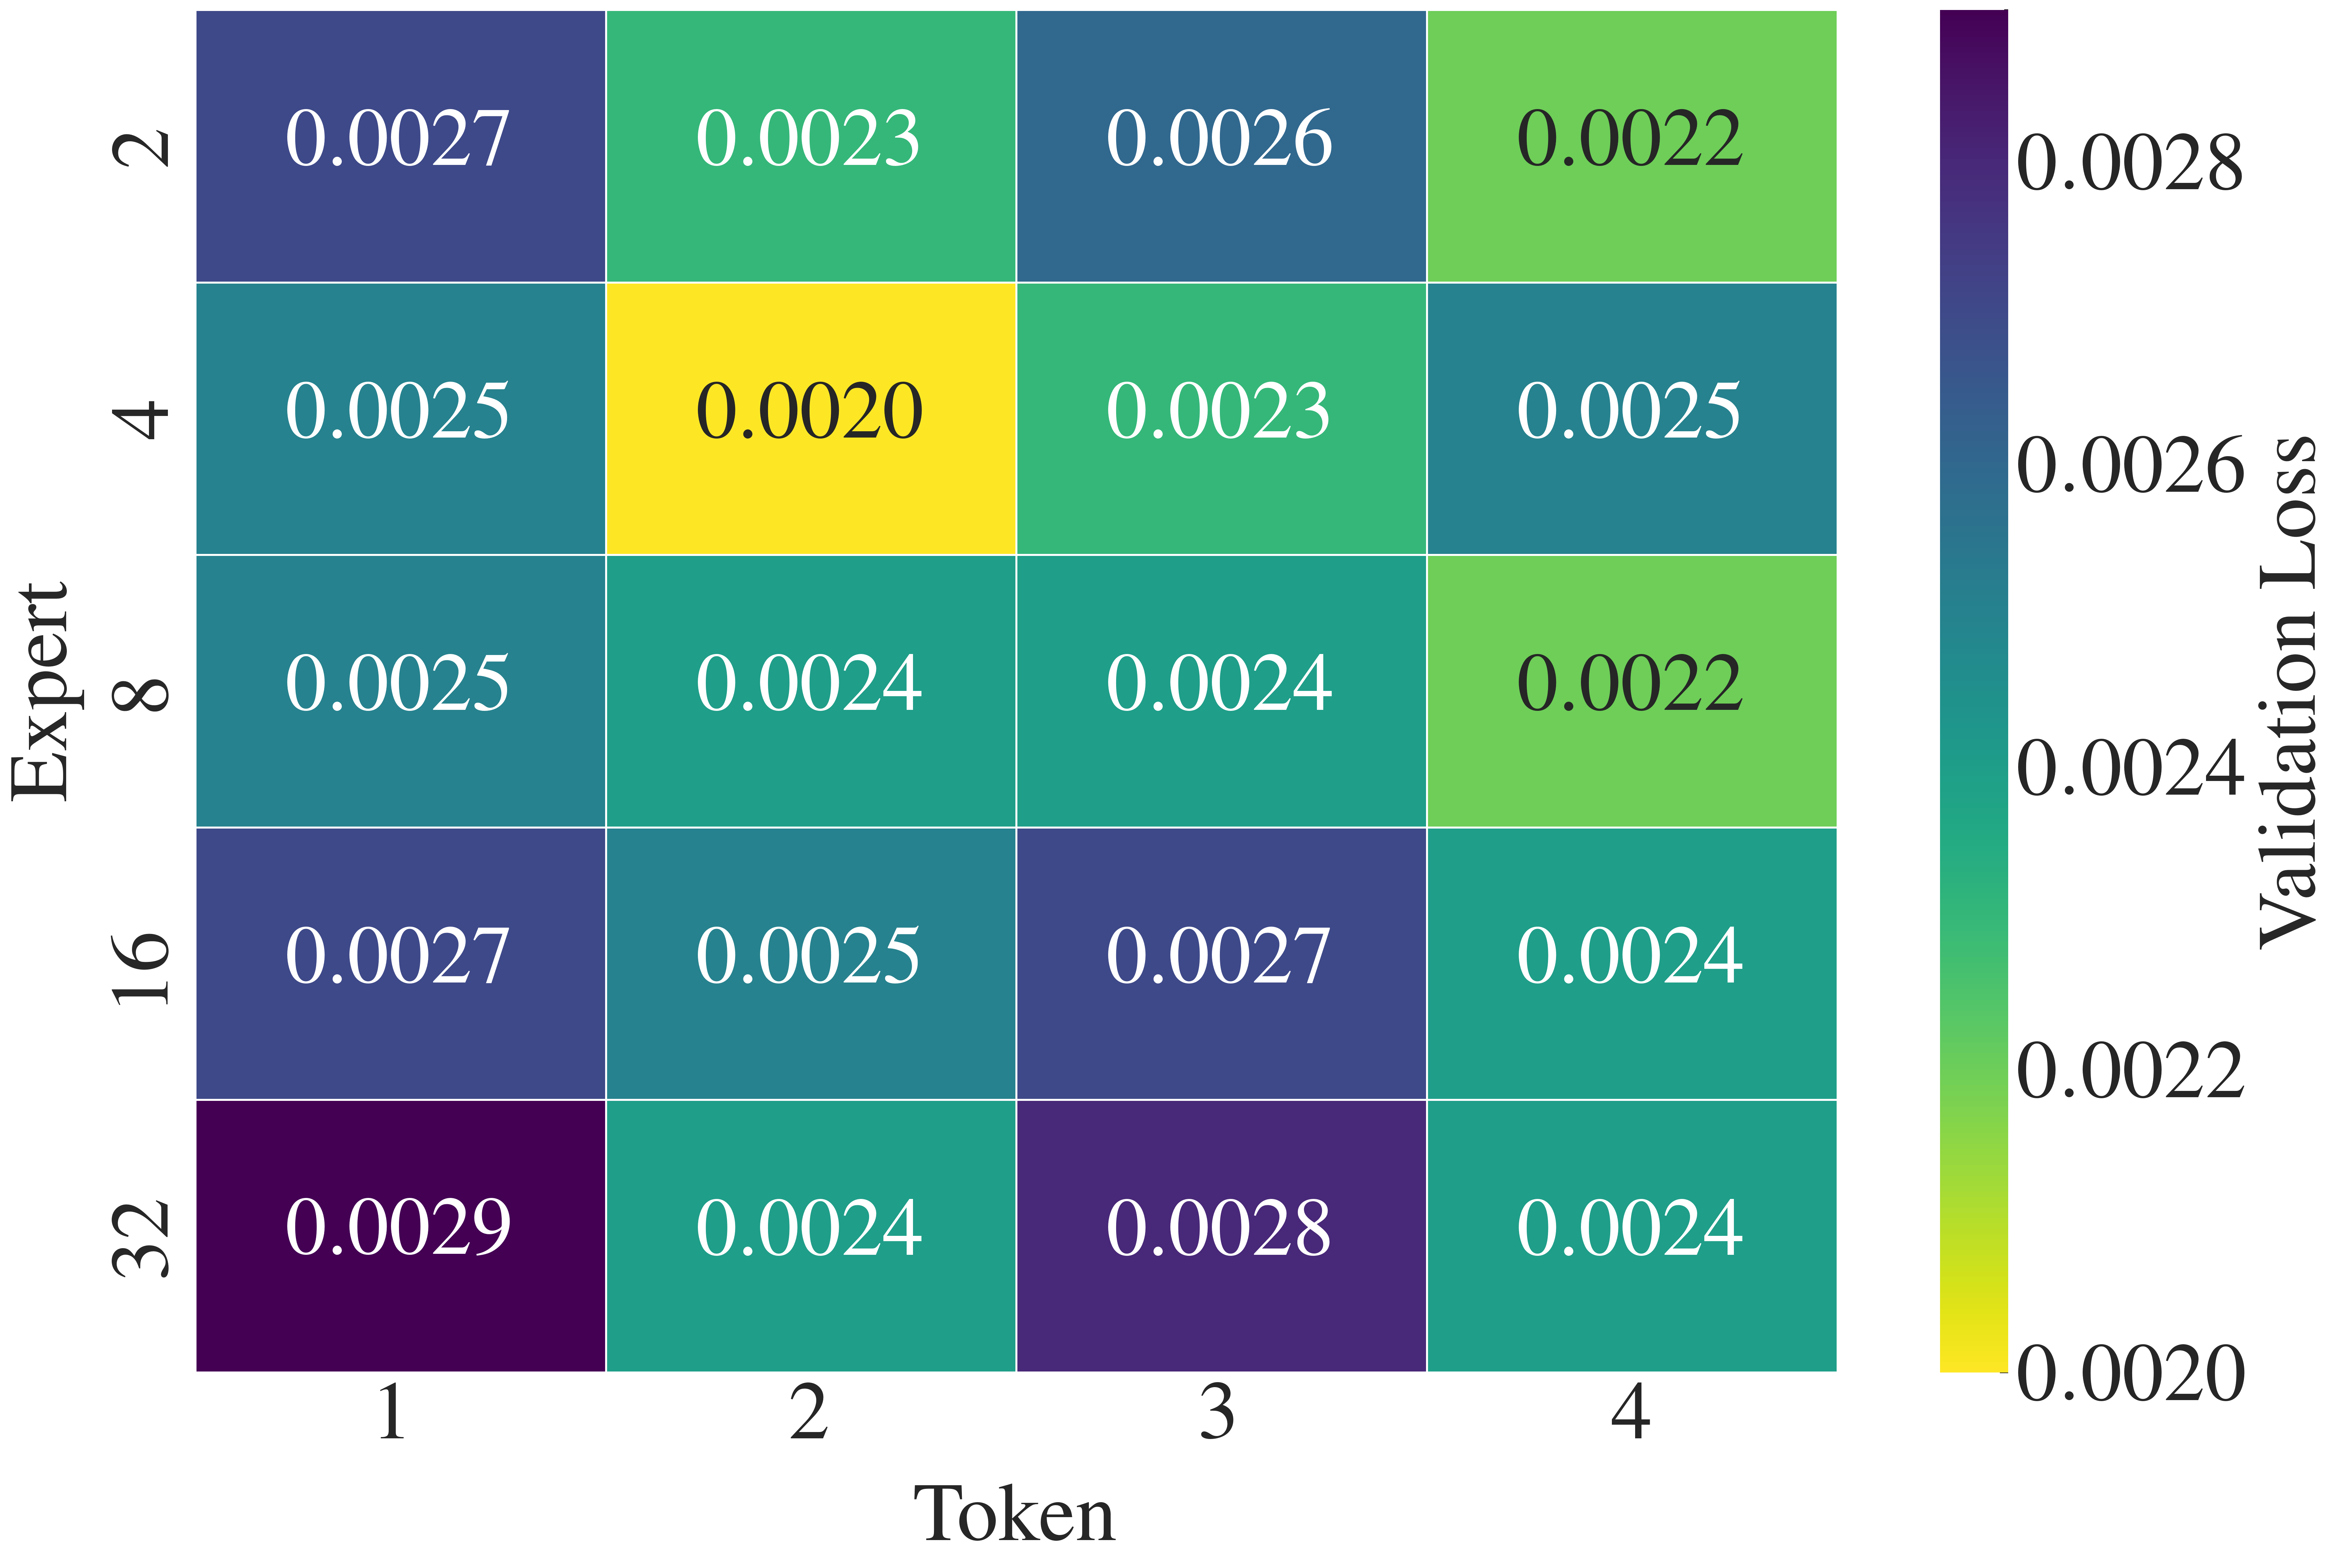

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scienceplots

# 设置全局字体大小（30号）及其他参数
plt.rcParams.update({
    'font.size': 30,               # 基础字体大小
    'axes.titlesize': 30,          # 标题字体大小
    'axes.labelsize': 30,          # 坐标轴标签字体大小
    'xtick.labelsize': 30,         # x轴刻度标签
    'ytick.labelsize': 30,         # y轴刻度标签
    'legend.fontsize': 30,         # 图例字体
    'figure.titlesize': 30         # 图形标题
})

# 准备数据
data = np.array([
    [0.0027, 0.0023, 0.0026, 0.0022],
    [0.0025, 0.0020, 0.0023, 0.0025],
    [0.0025, 0.0024, 0.0024, 0.0022],
    [0.0027, 0.0025, 0.0027, 0.0024],
    [0.0029, 0.0024, 0.0028, 0.0024]
])
columns = ['1', '2', '3', '4']
index = ['2', '4', '8', '16', '32']
df = pd.DataFrame(data, index=index, columns=columns)

# 绘制热力图（使用science+ieee+grid样式）
with plt.style.context(['science', 'ieee', 'grid']):
    fig, ax = plt.subplots(figsize=(12, 8))

    # 绘制热力图
    heatmap = sns.heatmap(
        data=df,
        annot=True,
        annot_kws={'size': 30},
        fmt=".4f",
        cmap='viridis_r',
        linewidths=0.5,
        linecolor='white',
        cbar_kws={'orientation': 'vertical', 'label': 'Validation Loss'}
    )

    # 设置坐标轴标签
    ax.set_xlabel("Token", labelpad=10)
    ax.set_ylabel("Expert", labelpad=10)

    # 调整色标字体（需单独设置）
    cbar = heatmap.collections[0].colorbar
    cbar.ax.tick_params(labelsize=30)  # 色标刻度字体
    cbar.set_label('Validation Loss', size=30)  # 色标标题字体

    plt.tight_layout()
    plt.savefig('Discussion_Expert_Token.pdf', dpi=600, bbox_inches='tight')
    plt.show()

# Moe Weight Visualization

## STEAD

### Weights

In [54]:
from Auxiliary import (
    ResCNNBlock, BiLSTMBlock, LayerNormalization, FeedForward,
    CustomLSTM, ActivationLSTMCell, TimeMoeSparseExpertsLayer,
    TimeMoeConfig, load_balancing_loss_func,TimeMoeAttention
)
from model_moe_gpt_PS2_CPU import MoEGlobalContextModule,MultiScaleFeatureExtractor,CNNResBlockStack,StackedBiLSTM,CRNNModule,CustomLSTM,TCNModule,PS1PickingBranch,PS2PickingBranch



import sys
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
from model_moe_gpt_PS2_CPU import IMG1

def normalize_data(data, mode='std'):
    data -= np.mean(data, axis=1, keepdims=True)
    if mode == 'std':
        std_val = np.std(data, axis=1, keepdims=True)
        std_val[std_val == 0] = 1.0
        data /= std_val
    elif mode == 'max':
        max_val = np.max(np.abs(data), axis=1, keepdims=True)
        max_val[max_val == 0] = 1.0
        data /= max_val
    else:
        raise ValueError(f"Unsupported norm_mode: {mode}")
    return data

def bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    filtered = np.zeros_like(data)
    for ch in range(data.shape[0]):
        filtered[ch] = filtfilt(b, a, data[ch])
    return filtered

def collect_expert_weights(model, input_data):
    model.eval()
    p_weights = {}  # {layer_name: expert_weights}
    s_weights = {}  # {layer_name: expert_weights}
    with torch.no_grad():
        # Process with MultiScaleFeatureExtractor
        feat = model.feature_extractor(input_data.permute(0, 2, 1))  # [batch, 64, seq_len]
        print(f"MultiScaleFeatureExtractor output shape: {feat.shape}")

        # Temporary dimension reduction for all MoE layers
        feat_reduced = feat.permute(0, 2, 1)  # [batch, seq_len, 64]
        weight = torch.nn.Parameter(torch.randn(16,64)).to(feat.device)  # [in_features=64, out_features=16]
        feat_reduced = torch.nn.functional.linear(feat_reduced, weight)  # [batch, seq_len, 16]
        feat_reduced = feat_reduced.permute(0, 2, 1)  # [batch, 16, seq_len]
        print(f"Reduced feat shape for all MoE layers: {feat_reduced.shape}")

        # Process context_dp0
        try:
            moe_out, moe_weights, router_logits = model.context_dp0(feat)
            print(f"context_dp0 router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_dp0'] = weights
            s_weights['context_dp0'] = weights
            print(f"context_dp0 expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_dp0: {str(e)}")

        # Process context_dp1
        try:
            moe_out, moe_weights, router_logits = model.context_dp1(feat)
            print(f"context_dp1 router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_dp1'] = weights
            s_weights['context_dp1'] = weights
            print(f"context_dp1 expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_dp1: {str(e)}")

        # Process context_d0
        try:
            moe_out, moe_weights, router_logits = model.context_d0(feat_reduced)
            print(f"context_d0 router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_d0'] = weights
            s_weights['context_d0'] = weights
            print(f"context_d0 expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_d0: {str(e)}")

        # Process context_d
        try:
            moe_out, moe_weights, router_logits = model.context_d(feat_reduced)
            print(f"context_d router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_d'] = weights
            s_weights['context_d'] = weights
            print(f"context_d expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_d: {str(e)}")

        # Process p_branch
        try:
            moe_out_p, moe_weights_p, p_router_logits = model.p_branch.attn_branch(feat_reduced)
            print(f"p_branch router_logits shape: {p_router_logits.shape}")
            p_router_probs = torch.softmax(p_router_logits, dim=-1)[0].cpu().numpy()
            p_weights['p_branch'] = p_router_probs.mean(axis=0) if p_router_probs.ndim == 2 else p_router_probs
            print(f"p_branch expert weights: {p_weights['p_branch']}")
        except Exception as e:
            print(f"Error processing p_branch: {str(e)}")

        # Process s_branch
        try:
            moe_out_s, moe_weights_s, s_router_logits = model.s_branch.attn_branch(feat_reduced)
            print(f"s_branch router_logits shape: {s_router_logits.shape}")
            s_router_probs = torch.softmax(s_router_logits, dim=-1)[0].cpu().numpy()
            s_weights['s_branch'] = s_router_probs.mean(axis=0) if s_router_probs.ndim == 2 else s_router_probs
            print(f"s_branch expert weights: {s_weights['s_branch']}")
        except Exception as e:
            print(f"Error processing s_branch: {str(e)}")

    return p_weights, s_weights

def visualize_expert_weights(p_weights, s_weights, input_signal, hdf5_path, trace_name, num_experts=4):
    with h5py.File(hdf5_path, 'r') as f:
        dataset = f['data'].get(trace_name)
        p_arrival = dataset.attrs['p_arrival_sample'] / 100
        s_arrival = dataset.attrs['s_arrival_sample'] / 100

    layers = list(set(p_weights.keys()) | set(s_weights.keys()))
    x = np.arange(num_experts)
    width = 0.15
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'][:len(layers)]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12), sharex=False)
    signal_time = np.linspace(0, input_signal.shape[1] / 100, input_signal.shape[1])
    ax1.plot(signal_time, input_signal[0].T.cpu().numpy()[0], label='Z')
    ax1.axvline(p_arrival, color='r', linestyle='--', label='P Arrival')
    ax1.axvline(s_arrival, color='g', linestyle='--', label='S Arrival')
    ax1.set_xlabel("Time (s)")
    ax1.set_ylabel("Amplitude")
    ax1.legend()
    ax1.set_title("Input Seismic Signal")

    for i, layer in enumerate(layers):
        p_vals = p_weights.get(layer, np.zeros(num_experts))
        s_vals = s_weights.get(layer, np.zeros(num_experts))
        offset = i * width - (len(layers) - 1) * width / 2
        ax2.bar(x + offset - width/2, p_vals, width/2, label=f"{layer} (P)", color=colors[i], alpha=0.6)
        ax2.bar(x + offset + width/2, s_vals, width/2, label=f"{layer} (S)", color=colors[i], alpha=0.9)

    ax2.set_xlabel("Expert Index")
    ax2.set_ylabel("Mean Routing Probability")
    ax2.set_title("Expert Utilization Across Layers (P and S Branches)")
    ax2.set_xticks(x)
    ax2.set_xticklabels([f"Expert {i+1}" for i in range(num_experts)])
    ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    ax2.grid(True, axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

# Modified IMG1 class with corrected in_dim
class IMG1(nn.Module):
    def __init__(self,
                 in_channels=3,
                 in_samples=6000,
                 drop_rate=0.1,
                 original_compatible=False,
                 use_moe=True,
                 num_experts=4,
                 num_experts_per_tok=4,
                 intermediate_size=256,
                 hidden_act="gelu",
                 router_aux_loss_factor=0.01,
                 **kwargs):
        super().__init__()
        self.in_channels = in_channels
        self.in_samples = in_samples
        self.drop_rate = drop_rate
        self.original_compatible = original_compatible

        self.filters = [8, 16, 16, 32, 32, 64, 64]
        self.kernel_sizes = [11, 9, 7, 7, 5, 5, 3]
        self.res_cnn_kernels = [3, 3, 3, 3, 2, 3, 2]

        self.feature_extractor = MultiScaleFeatureExtractor(
            in_channels=self.in_channels,
            filters=self.filters,
            kernel_sizes=self.kernel_sizes,
            in_samples=self.in_samples
        )
        moe_cfg_64 = TimeMoeConfig(
            hidden_size=64,
            num_experts=num_experts,
            num_experts_per_tok=num_experts_per_tok,
            intermediate_size=4*64,
            hidden_act=hidden_act,
            router_aux_loss_factor=router_aux_loss_factor
        )
        self.context_dp0 = MoEGlobalContextModule(64, drop_rate, eps=1e-5, moe_config=moe_cfg_64)
        self.context_dp1 = MoEGlobalContextModule(64, drop_rate, eps=1e-5, moe_config=moe_cfg_64)

        self.cnn_res_stack = CNNResBlockStack(
            kernel_list=self.res_cnn_kernels,
            out_channels=self.filters[-1],
            dropout_rate=self.drop_rate
        )
        self.bi_lstm = StackedBiLSTM(
            num_blocks=3,
            input_dim=64,
            dropout_rate=self.drop_rate,
            original_compatible=original_compatible
        )
        moe_cfg_16 = TimeMoeConfig(
            hidden_size=16,
            num_experts=num_experts,
            num_experts_per_tok=num_experts_per_tok,
            intermediate_size=4*16,
            hidden_act=hidden_act,
            router_aux_loss_factor=router_aux_loss_factor
        )
        self.context_d0 = MoEGlobalContextModule(16, drop_rate, eps=1e-5, moe_config=moe_cfg_16)
        self.context_d = MoEGlobalContextModule(16, drop_rate, eps=1e-5, moe_config=moe_cfg_16)

        self.p_branch = PS2PickingBranch(
            in_dim=16,  # Corrected to match bi_lstm output
            out_samples=self.in_samples,
            drop_rate=self.drop_rate,
            filters=self.filters,
            kernel_sizes=self.kernel_sizes,
            original_compatible=original_compatible,
            moe_config=moe_cfg_16
        )
        self.s_branch = PS2PickingBranch(
            in_dim=16,  # Corrected to match bi_lstm output
            out_samples=self.in_samples,
            drop_rate=self.drop_rate,
            filters=self.filters,
            kernel_sizes=self.kernel_sizes,
            original_compatible=original_compatible,
            moe_config=moe_cfg_16
        )

    def forward(self, x, logits=False):
        x = x.permute(0, 2, 1)
        feat = self.feature_extractor(x)
        feat, _, router_dp0 = self.context_dp0(feat)
        feat, _, router_dp1 = self.context_dp1(feat)
        feat = self.cnn_res_stack(feat)
        feat = self.bi_lstm(feat)
        feat, _, router_d0 = self.context_d0(feat)
        feat, _, router_d = self.context_d(feat)

        p_pred = self.p_branch(feat, logits=logits)
        s_pred = self.s_branch(feat, logits=logits)

        router_list = []
        if router_dp0 is not None: router_list.append(router_dp0)
        if router_dp1 is not None: router_list.append(router_dp1)
        if router_d0 is not None: router_list.append(router_d0)
        if router_d is not None: router_list.append(router_d)

        balance_loss = torch.tensor(0.0, device=x.device)
        if router_list:
            balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))

        return (p_pred, s_pred), balance_loss

# Usage example
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hdf5_path = "/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.hdf5"
trace_name = 'GO02.C_20130925131520_EV'

# Load and preprocess data
with h5py.File(hdf5_path, 'r') as f:
    dataset = f['data'].get(trace_name)
    normalized = dataset[:].T
normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
normalized = normalize_data(normalized, 'std')
data = torch.from_numpy(normalized.T).unsqueeze(0).to(device)


# Load model
model = IMG1(num_experts=4, num_experts_per_tok=4).to(device)

# Collect and visualize expert weights
p_weights, s_weights = collect_expert_weights(model, data)

# 将 expert 权重转换为 DataFrame
def weights_to_dataframe(weights_dict, label):
    df = pd.DataFrame.from_dict(weights_dict, orient='index')
    df.columns = [f'expert_{i}' for i in range(df.shape[1])]
    df.index.name = 'layer'
    df['branch'] = label
    return df.reset_index()

# 转换为 DataFrame
df_p = weights_to_dataframe(p_weights, 'P')
df_s = weights_to_dataframe(s_weights, 'S')

# 合并两个 DataFrame
df_stead= pd.concat([df_p, df_s], ignore_index=True)

# 打印 DataFrame 结果

df_stead.to_csv('/home/yuan/code/SeisMoE/data/expert_weights/expert_weights_stead.csv', index=False)

df_stead

# visualize_expert_weights(p_weights, s_weights, input_signal, hdf5_path, trace_name, num_experts=4)

RuntimeError: CUDA error: unknown error
CUDA kernel errors might be asynchronously reported at some other API call,so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1.

### Draw

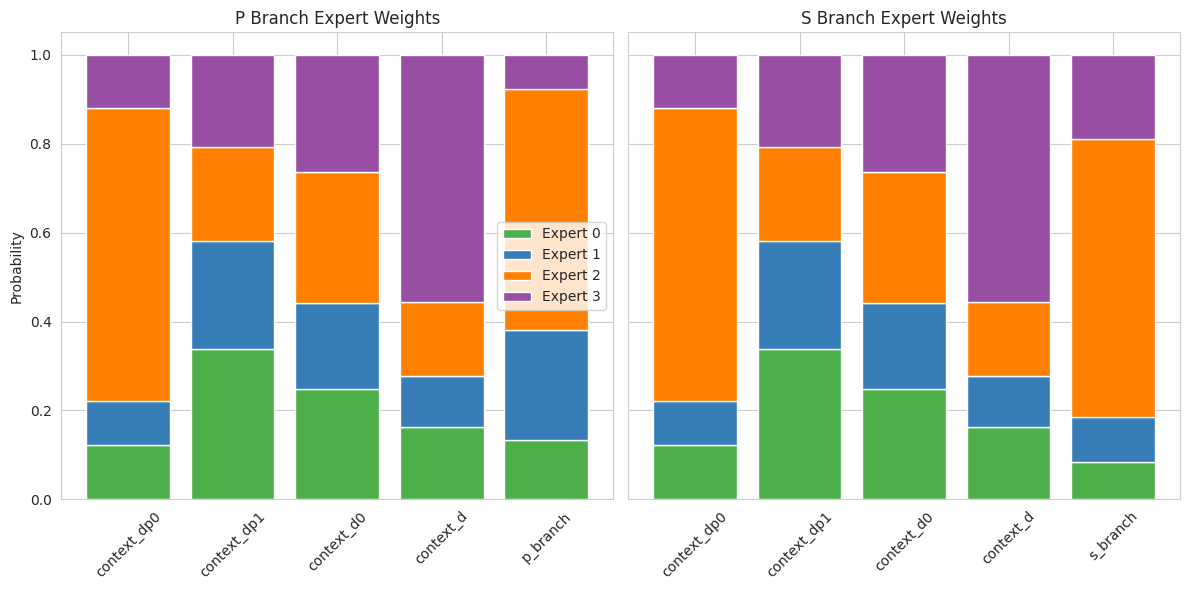

In [4]:
import matplotlib.pyplot as plt

# 筛选 P 和 S 分支的数据
df_p_plot = df_stead[df_stead['branch'] == 'P'].set_index('layer').drop(columns='branch')
df_s_plot = df_stead[df_stead['branch'] == 'S'].set_index('layer').drop(columns='branch')

# 确保层顺序一致
moe_layers = ['context_dp0', 'context_dp1', 'context_d0', 'context_d', 'p_branch']
df_p_plot = df_p_plot.loc[moe_layers]
df_s_plot = df_s_plot.loc[[l.replace('p_branch', 's_branch') if 'p_branch' in l else l for l in moe_layers]]


# 绘图
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
colors = ['#4daf4a', '#377eb8', '#ff7f00', '#984ea3']
x = range(len(moe_layers))

# 绘制 P 分支
bottom = np.zeros(len(moe_layers))
for i in range(4):
    axes[0].bar(x, df_p_plot[f'expert_{i}'], bottom=bottom, color=colors[i], label=f'Expert {i}')
    bottom += df_p_plot[f'expert_{i}'].values
axes[0].set_xticks(x)
axes[0].set_xticklabels(moe_layers, rotation=45)
axes[0].set_title('P Branch Expert Weights')
axes[0].set_ylabel('Probability')
axes[0].legend()

# 绘制 S 分支
bottom = np.zeros(len(moe_layers))
for i in range(4):
    axes[1].bar(x, df_s_plot[f'expert_{i}'], bottom=bottom, color=colors[i], label=f'Expert {i}')
    bottom += df_s_plot[f'expert_{i}'].values
axes[1].set_xticks(x)
axes[1].set_xticklabels([l.replace('p_branch', 's_branch') for l in moe_layers], rotation=45)
axes[1].set_title('S Branch Expert Weights')

plt.tight_layout()
plt.show()


## Txed

### Weights

In [5]:
from Auxiliary import (
    ResCNNBlock, BiLSTMBlock, LayerNormalization, FeedForward,
    CustomLSTM, ActivationLSTMCell, TimeMoeSparseExpertsLayer,
    TimeMoeConfig, load_balancing_loss_func,TimeMoeAttention
)
from model_moe_gpt_PS2_CPU import MoEGlobalContextModule,MultiScaleFeatureExtractor,CNNResBlockStack,StackedBiLSTM,CRNNModule,CustomLSTM,TCNModule,PS1PickingBranch,PS2PickingBranch



import sys
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
from model_moe_gpt_PS2_CPU import IMG1

def normalize_data(data, mode='std'):
    data -= np.mean(data, axis=1, keepdims=True)
    if mode == 'std':
        std_val = np.std(data, axis=1, keepdims=True)
        std_val[std_val == 0] = 1.0
        data /= std_val
    elif mode == 'max':
        max_val = np.max(np.abs(data), axis=1, keepdims=True)
        max_val[max_val == 0] = 1.0
        data /= max_val
    else:
        raise ValueError(f"Unsupported norm_mode: {mode}")
    return data

def bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    filtered = np.zeros_like(data)
    for ch in range(data.shape[0]):
        filtered[ch] = filtfilt(b, a, data[ch])
    return filtered

def collect_expert_weights(model, input_data):
    model.eval()
    p_weights = {}  # {layer_name: expert_weights}
    s_weights = {}  # {layer_name: expert_weights}
    with torch.no_grad():
        # Process with MultiScaleFeatureExtractor
        feat = model.feature_extractor(input_data.permute(0, 2, 1))  # [batch, 64, seq_len]
        print(f"MultiScaleFeatureExtractor output shape: {feat.shape}")

        # Temporary dimension reduction for all MoE layers
        feat_reduced = feat.permute(0, 2, 1)  # [batch, seq_len, 64]
        weight = torch.nn.Parameter(torch.randn(16,64)).to(feat.device)  # [in_features=64, out_features=16]
        feat_reduced = torch.nn.functional.linear(feat_reduced, weight)  # [batch, seq_len, 16]
        feat_reduced = feat_reduced.permute(0, 2, 1)  # [batch, 16, seq_len]
        print(f"Reduced feat shape for all MoE layers: {feat_reduced.shape}")

        # Process context_dp0
        try:
            moe_out, moe_weights, router_logits = model.context_dp0(feat)
            print(f"context_dp0 router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_dp0'] = weights
            s_weights['context_dp0'] = weights
            print(f"context_dp0 expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_dp0: {str(e)}")

        # Process context_dp1
        try:
            moe_out, moe_weights, router_logits = model.context_dp1(feat)
            print(f"context_dp1 router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_dp1'] = weights
            s_weights['context_dp1'] = weights
            print(f"context_dp1 expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_dp1: {str(e)}")

        # Process context_d0
        try:
            moe_out, moe_weights, router_logits = model.context_d0(feat_reduced)
            print(f"context_d0 router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_d0'] = weights
            s_weights['context_d0'] = weights
            print(f"context_d0 expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_d0: {str(e)}")

        # Process context_d
        try:
            moe_out, moe_weights, router_logits = model.context_d(feat_reduced)
            print(f"context_d router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_d'] = weights
            s_weights['context_d'] = weights
            print(f"context_d expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_d: {str(e)}")

        # Process p_branch
        try:
            moe_out_p, moe_weights_p, p_router_logits = model.p_branch.attn_branch(feat_reduced)
            print(f"p_branch router_logits shape: {p_router_logits.shape}")
            p_router_probs = torch.softmax(p_router_logits, dim=-1)[0].cpu().numpy()
            p_weights['p_branch'] = p_router_probs.mean(axis=0) if p_router_probs.ndim == 2 else p_router_probs
            print(f"p_branch expert weights: {p_weights['p_branch']}")
        except Exception as e:
            print(f"Error processing p_branch: {str(e)}")

        # Process s_branch
        try:
            moe_out_s, moe_weights_s, s_router_logits = model.s_branch.attn_branch(feat_reduced)
            print(f"s_branch router_logits shape: {s_router_logits.shape}")
            s_router_probs = torch.softmax(s_router_logits, dim=-1)[0].cpu().numpy()
            s_weights['s_branch'] = s_router_probs.mean(axis=0) if s_router_probs.ndim == 2 else s_router_probs
            print(f"s_branch expert weights: {s_weights['s_branch']}")
        except Exception as e:
            print(f"Error processing s_branch: {str(e)}")

    return p_weights, s_weights

def visualize_expert_weights(p_weights, s_weights, input_signal, hdf5_path, trace_name, num_experts=4):
    with h5py.File(hdf5_path, 'r') as f:
        dataset = f['data'].get(trace_name)
        p_arrival = dataset.attrs['p_arrival_sample'] / 100
        s_arrival = dataset.attrs['s_arrival_sample'] / 100

    layers = list(set(p_weights.keys()) | set(s_weights.keys()))
    x = np.arange(num_experts)
    width = 0.15
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'][:len(layers)]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12), sharex=False)
    signal_time = np.linspace(0, input_signal.shape[1] / 100, input_signal.shape[1])
    ax1.plot(signal_time, input_signal[0].T.cpu().numpy()[0], label='Z')
    ax1.axvline(p_arrival, color='r', linestyle='--', label='P Arrival')
    ax1.axvline(s_arrival, color='g', linestyle='--', label='S Arrival')
    ax1.set_xlabel("Time (s)")
    ax1.set_ylabel("Amplitude")
    ax1.legend()
    ax1.set_title("Input Seismic Signal")

    for i, layer in enumerate(layers):
        p_vals = p_weights.get(layer, np.zeros(num_experts))
        s_vals = s_weights.get(layer, np.zeros(num_experts))
        offset = i * width - (len(layers) - 1) * width / 2
        ax2.bar(x + offset - width/2, p_vals, width/2, label=f"{layer} (P)", color=colors[i], alpha=0.6)
        ax2.bar(x + offset + width/2, s_vals, width/2, label=f"{layer} (S)", color=colors[i], alpha=0.9)

    ax2.set_xlabel("Expert Index")
    ax2.set_ylabel("Mean Routing Probability")
    ax2.set_title("Expert Utilization Across Layers (P and S Branches)")
    ax2.set_xticks(x)
    ax2.set_xticklabels([f"Expert {i+1}" for i in range(num_experts)])
    ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    ax2.grid(True, axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

# Modified IMG1 class with corrected in_dim
class IMG1(nn.Module):
    def __init__(self,
                 in_channels=3,
                 in_samples=6000,
                 drop_rate=0.1,
                 original_compatible=False,
                 use_moe=True,
                 num_experts=4,
                 num_experts_per_tok=4,
                 intermediate_size=256,
                 hidden_act="gelu",
                 router_aux_loss_factor=0.01,
                 **kwargs):
        super().__init__()
        self.in_channels = in_channels
        self.in_samples = in_samples
        self.drop_rate = drop_rate
        self.original_compatible = original_compatible

        self.filters = [8, 16, 16, 32, 32, 64, 64]
        self.kernel_sizes = [11, 9, 7, 7, 5, 5, 3]
        self.res_cnn_kernels = [3, 3, 3, 3, 2, 3, 2]

        self.feature_extractor = MultiScaleFeatureExtractor(
            in_channels=self.in_channels,
            filters=self.filters,
            kernel_sizes=self.kernel_sizes,
            in_samples=self.in_samples
        )
        moe_cfg_64 = TimeMoeConfig(
            hidden_size=64,
            num_experts=num_experts,
            num_experts_per_tok=num_experts_per_tok,
            intermediate_size=4*64,
            hidden_act=hidden_act,
            router_aux_loss_factor=router_aux_loss_factor
        )
        self.context_dp0 = MoEGlobalContextModule(64, drop_rate, eps=1e-5, moe_config=moe_cfg_64)
        self.context_dp1 = MoEGlobalContextModule(64, drop_rate, eps=1e-5, moe_config=moe_cfg_64)

        self.cnn_res_stack = CNNResBlockStack(
            kernel_list=self.res_cnn_kernels,
            out_channels=self.filters[-1],
            dropout_rate=self.drop_rate
        )
        self.bi_lstm = StackedBiLSTM(
            num_blocks=3,
            input_dim=64,
            dropout_rate=self.drop_rate,
            original_compatible=original_compatible
        )
        moe_cfg_16 = TimeMoeConfig(
            hidden_size=16,
            num_experts=num_experts,
            num_experts_per_tok=num_experts_per_tok,
            intermediate_size=4*16,
            hidden_act=hidden_act,
            router_aux_loss_factor=router_aux_loss_factor
        )
        self.context_d0 = MoEGlobalContextModule(16, drop_rate, eps=1e-5, moe_config=moe_cfg_16)
        self.context_d = MoEGlobalContextModule(16, drop_rate, eps=1e-5, moe_config=moe_cfg_16)

        self.p_branch = PS2PickingBranch(
            in_dim=16,  # Corrected to match bi_lstm output
            out_samples=self.in_samples,
            drop_rate=self.drop_rate,
            filters=self.filters,
            kernel_sizes=self.kernel_sizes,
            original_compatible=original_compatible,
            moe_config=moe_cfg_16
        )
        self.s_branch = PS2PickingBranch(
            in_dim=16,  # Corrected to match bi_lstm output
            out_samples=self.in_samples,
            drop_rate=self.drop_rate,
            filters=self.filters,
            kernel_sizes=self.kernel_sizes,
            original_compatible=original_compatible,
            moe_config=moe_cfg_16
        )

    def forward(self, x, logits=False):
        x = x.permute(0, 2, 1)
        feat = self.feature_extractor(x)
        feat, _, router_dp0 = self.context_dp0(feat)
        feat, _, router_dp1 = self.context_dp1(feat)
        feat = self.cnn_res_stack(feat)
        feat = self.bi_lstm(feat)
        feat, _, router_d0 = self.context_d0(feat)
        feat, _, router_d = self.context_d(feat)

        p_pred = self.p_branch(feat, logits=logits)
        s_pred = self.s_branch(feat, logits=logits)

        router_list = []
        if router_dp0 is not None: router_list.append(router_dp0)
        if router_dp1 is not None: router_list.append(router_dp1)
        if router_d0 is not None: router_list.append(router_d0)
        if router_d is not None: router_list.append(router_d)

        balance_loss = torch.tensor(0.0, device=x.device)
        if router_list:
            balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))

        return (p_pred, s_pred), balance_loss

# Usage example
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hdf5_path = "/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.hdf5"
trace_name = 'bucket390$537,:3,:6000'

# Load and preprocess data
with h5py.File(hdf5_path, 'r') as f:
        if 'data' not in f:
            raise KeyError("HDF5文件中缺少'data'组")

        group = trace_name.split('$')[0].strip()
        index = int(trace_name.split('$')[1].split(',')[0].strip())

        dataset = f['data'].get(group)
        normalized = dataset[index, :, :].astype(np.float32)

normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
normalized = normalize_data(normalized, 'std')
data = torch.from_numpy(normalized.T).unsqueeze(0).to(device)
input_signal = data.clone()


# Load model
model = IMG1(num_experts=4, num_experts_per_tok=4).to(device)

# Collect and visualize expert weights
p_weights, s_weights = collect_expert_weights(model, data)

# 将 expert 权重转换为 DataFrame
def weights_to_dataframe(weights_dict, label):
    df = pd.DataFrame.from_dict(weights_dict, orient='index')
    df.columns = [f'expert_{i}' for i in range(df.shape[1])]
    df.index.name = 'layer'
    df['branch'] = label
    return df.reset_index()

# 转换为 DataFrame
df_p = weights_to_dataframe(p_weights, 'P')
df_s = weights_to_dataframe(s_weights, 'S')

# 合并两个 DataFrame
df_txed= pd.concat([df_p, df_s], ignore_index=True)

# 打印 DataFrame 结果

df_txed.to_csv('/home/yuan/code/SeisMoE/data/expert_weights/expert_weights_txed.csv', index=False)

df_txed

# visualize_expert_weights(p_weights, s_weights, input_signal, hdf5_path, trace_name, num_experts=4)

MultiScaleFeatureExtractor output shape: torch.Size([1, 64, 47])
Reduced feat shape for all MoE layers: torch.Size([1, 16, 47])
context_dp0 router_logits shape: torch.Size([47, 4])
context_dp0 expert weights: [0.26948908 0.28535607 0.32699585 0.11815905]
context_dp1 router_logits shape: torch.Size([47, 4])
context_dp1 expert weights: [0.2522505  0.18938583 0.28512824 0.27323544]
context_d0 router_logits shape: torch.Size([47, 4])
context_d0 expert weights: [0.12233437 0.07125658 0.29264832 0.51376075]
context_d router_logits shape: torch.Size([47, 4])
context_d expert weights: [0.2977148  0.32230383 0.22015281 0.15982856]
p_branch router_logits shape: torch.Size([47, 4])
p_branch expert weights: [0.34505373 0.12853847 0.28428704 0.2421208 ]
s_branch router_logits shape: torch.Size([47, 4])
s_branch expert weights: [0.19376408 0.3522983  0.09797054 0.35596707]


,layer,expert_0,expert_1,expert_2,expert_3,branch
0,context_dp0,0.269489,0.285356,0.326996,0.118159,P
1,context_dp1,0.252250,0.189386,0.285128,0.273235,P
2,context_d0,0.122334,0.071257,0.292648,0.513761,P
3,context_d,0.297715,0.322304,0.220153,0.159829,P
4,p_branch,0.345054,0.128538,0.284287,0.242121,P
5,context_dp0,0.269489,0.285356,0.326996,0.118159,S
6,context_dp1,0.252250,0.189386,0.285128,0.273235,S
7,context_d0,0.122334,0.071257,0.292648,0.513761,S
8,context_d,0.297715,0.322304,0.220153,0.159829,S
9,s_branch,0.193764,0.352298,0.097971,0.355967,S


### Draw

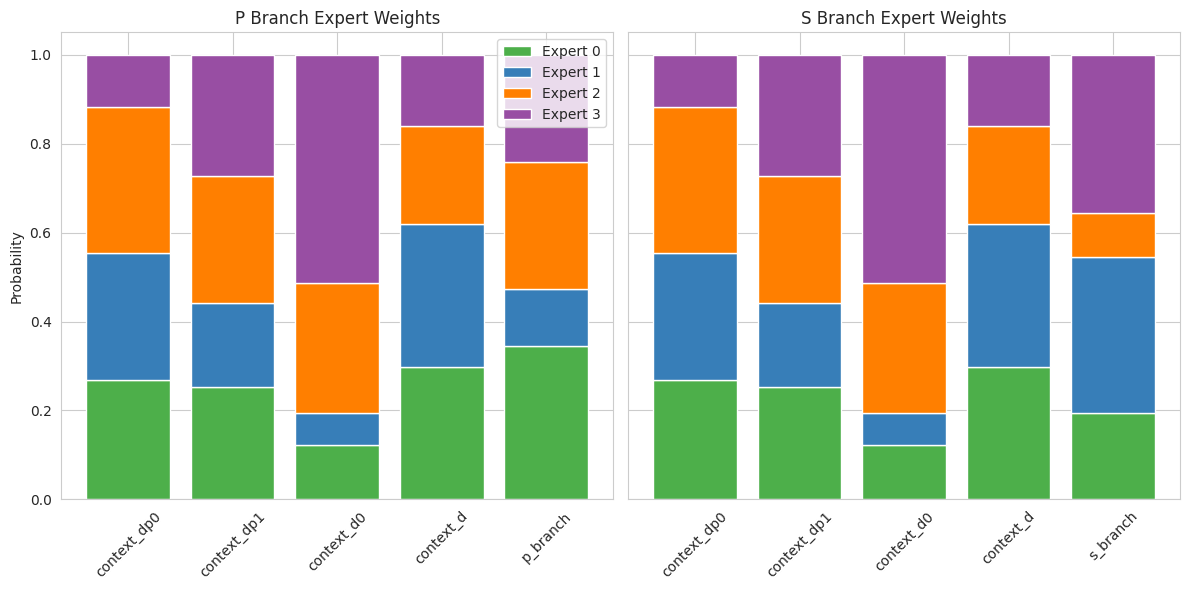

In [6]:
import matplotlib.pyplot as plt

# 筛选 P 和 S 分支的数据
df_p_plot = df_txed[df_txed['branch'] == 'P'].set_index('layer').drop(columns='branch')
df_s_plot = df_txed[df_txed['branch'] == 'S'].set_index('layer').drop(columns='branch')

# 确保层顺序一致
moe_layers = ['context_dp0', 'context_dp1', 'context_d0', 'context_d', 'p_branch']
df_p_plot = df_p_plot.loc[moe_layers]
df_s_plot = df_s_plot.loc[[l.replace('p_branch', 's_branch') if 'p_branch' in l else l for l in moe_layers]]


# 绘图
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
colors = ['#4daf4a', '#377eb8', '#ff7f00', '#984ea3']
x = range(len(moe_layers))

# 绘制 P 分支
bottom = np.zeros(len(moe_layers))
for i in range(4):
    axes[0].bar(x, df_p_plot[f'expert_{i}'], bottom=bottom, color=colors[i], label=f'Expert {i}')
    bottom += df_p_plot[f'expert_{i}'].values
axes[0].set_xticks(x)
axes[0].set_xticklabels(moe_layers, rotation=45)
axes[0].set_title('P Branch Expert Weights')
axes[0].set_ylabel('Probability')
axes[0].legend()

# 绘制 S 分支
bottom = np.zeros(len(moe_layers))
for i in range(4):
    axes[1].bar(x, df_s_plot[f'expert_{i}'], bottom=bottom, color=colors[i], label=f'Expert {i}')
    bottom += df_s_plot[f'expert_{i}'].values
axes[1].set_xticks(x)
axes[1].set_xticklabels([l.replace('p_branch', 's_branch') for l in moe_layers], rotation=45)
axes[1].set_title('S Branch Expert Weights')

plt.tight_layout()
plt.show()


## Instance

### Weights

In [7]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]="2"

from Auxiliary import (
    ResCNNBlock, BiLSTMBlock, LayerNormalization, FeedForward,
    CustomLSTM, ActivationLSTMCell, TimeMoeSparseExpertsLayer,
    TimeMoeConfig, load_balancing_loss_func,TimeMoeAttention
)
from model_moe_gpt_PS2_CPU import MoEGlobalContextModule,MultiScaleFeatureExtractor,CNNResBlockStack,StackedBiLSTM,CRNNModule,CustomLSTM,TCNModule,PS1PickingBranch,PS2PickingBranch



import sys
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
from model_moe_gpt_PS2_CPU import IMG1

def normalize_data(data, mode='std'):
    data -= np.mean(data, axis=1, keepdims=True)
    if mode == 'std':
        std_val = np.std(data, axis=1, keepdims=True)
        std_val[std_val == 0] = 1.0
        data /= std_val
    elif mode == 'max':
        max_val = np.max(np.abs(data), axis=1, keepdims=True)
        max_val[max_val == 0] = 1.0
        data /= max_val
    else:
        raise ValueError(f"Unsupported norm_mode: {mode}")
    return data

def bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    filtered = np.zeros_like(data)
    for ch in range(data.shape[0]):
        filtered[ch] = filtfilt(b, a, data[ch])
    return filtered

def collect_expert_weights(model, input_data):
    model.eval()
    p_weights = {}  # {layer_name: expert_weights}
    s_weights = {}  # {layer_name: expert_weights}
    with torch.no_grad():
        # Process with MultiScaleFeatureExtractor
        feat = model.feature_extractor(input_data.permute(0, 2, 1))  # [batch, 64, seq_len]
        print(f"MultiScaleFeatureExtractor output shape: {feat.shape}")

        # Temporary dimension reduction for all MoE layers
        feat_reduced = feat.permute(0, 2, 1)  # [batch, seq_len, 64]
        weight = torch.nn.Parameter(torch.randn(16,64)).to(feat.device)  # [in_features=64, out_features=16]
        feat_reduced = torch.nn.functional.linear(feat_reduced, weight)  # [batch, seq_len, 16]
        feat_reduced = feat_reduced.permute(0, 2, 1)  # [batch, 16, seq_len]
        print(f"Reduced feat shape for all MoE layers: {feat_reduced.shape}")

        # Process context_dp0
        try:
            moe_out, moe_weights, router_logits = model.context_dp0(feat)
            print(f"context_dp0 router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_dp0'] = weights
            s_weights['context_dp0'] = weights
            print(f"context_dp0 expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_dp0: {str(e)}")

        # Process context_dp1
        try:
            moe_out, moe_weights, router_logits = model.context_dp1(feat)
            print(f"context_dp1 router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_dp1'] = weights
            s_weights['context_dp1'] = weights
            print(f"context_dp1 expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_dp1: {str(e)}")

        # Process context_d0
        try:
            moe_out, moe_weights, router_logits = model.context_d0(feat_reduced)
            print(f"context_d0 router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_d0'] = weights
            s_weights['context_d0'] = weights
            print(f"context_d0 expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_d0: {str(e)}")

        # Process context_d
        try:
            moe_out, moe_weights, router_logits = model.context_d(feat_reduced)
            print(f"context_d router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_d'] = weights
            s_weights['context_d'] = weights
            print(f"context_d expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_d: {str(e)}")

        # Process p_branch
        try:
            moe_out_p, moe_weights_p, p_router_logits = model.p_branch.attn_branch(feat_reduced)
            print(f"p_branch router_logits shape: {p_router_logits.shape}")
            p_router_probs = torch.softmax(p_router_logits, dim=-1)[0].cpu().numpy()
            p_weights['p_branch'] = p_router_probs.mean(axis=0) if p_router_probs.ndim == 2 else p_router_probs
            print(f"p_branch expert weights: {p_weights['p_branch']}")
        except Exception as e:
            print(f"Error processing p_branch: {str(e)}")

        # Process s_branch
        try:
            moe_out_s, moe_weights_s, s_router_logits = model.s_branch.attn_branch(feat_reduced)
            print(f"s_branch router_logits shape: {s_router_logits.shape}")
            s_router_probs = torch.softmax(s_router_logits, dim=-1)[0].cpu().numpy()
            s_weights['s_branch'] = s_router_probs.mean(axis=0) if s_router_probs.ndim == 2 else s_router_probs
            print(f"s_branch expert weights: {s_weights['s_branch']}")
        except Exception as e:
            print(f"Error processing s_branch: {str(e)}")

    return p_weights, s_weights

def visualize_expert_weights(p_weights, s_weights, input_signal, hdf5_path, trace_name, num_experts=4):
    with h5py.File(hdf5_path, 'r') as f:
        dataset = f['data'].get(trace_name)
        p_arrival = dataset.attrs['p_arrival_sample'] / 100
        s_arrival = dataset.attrs['s_arrival_sample'] / 100

    layers = list(set(p_weights.keys()) | set(s_weights.keys()))
    x = np.arange(num_experts)
    width = 0.15
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'][:len(layers)]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12), sharex=False)
    signal_time = np.linspace(0, input_signal.shape[1] / 100, input_signal.shape[1])
    ax1.plot(signal_time, input_signal[0].T.cpu().numpy()[0], label='Z')
    ax1.axvline(p_arrival, color='r', linestyle='--', label='P Arrival')
    ax1.axvline(s_arrival, color='g', linestyle='--', label='S Arrival')
    ax1.set_xlabel("Time (s)")
    ax1.set_ylabel("Amplitude")
    ax1.legend()
    ax1.set_title("Input Seismic Signal")

    for i, layer in enumerate(layers):
        p_vals = p_weights.get(layer, np.zeros(num_experts))
        s_vals = s_weights.get(layer, np.zeros(num_experts))
        offset = i * width - (len(layers) - 1) * width / 2
        ax2.bar(x + offset - width/2, p_vals, width/2, label=f"{layer} (P)", color=colors[i], alpha=0.6)
        ax2.bar(x + offset + width/2, s_vals, width/2, label=f"{layer} (S)", color=colors[i], alpha=0.9)

    ax2.set_xlabel("Expert Index")
    ax2.set_ylabel("Mean Routing Probability")
    ax2.set_title("Expert Utilization Across Layers (P and S Branches)")
    ax2.set_xticks(x)
    ax2.set_xticklabels([f"Expert {i+1}" for i in range(num_experts)])
    ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    ax2.grid(True, axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

# Modified IMG1 class with corrected in_dim
class IMG1(nn.Module):
    def __init__(self,
                 in_channels=3,
                 in_samples=6000,
                 drop_rate=0.1,
                 original_compatible=False,
                 use_moe=True,
                 num_experts=4,
                 num_experts_per_tok=4,
                 intermediate_size=256,
                 hidden_act="gelu",
                 router_aux_loss_factor=0.01,
                 **kwargs):
        super().__init__()
        self.in_channels = in_channels
        self.in_samples = in_samples
        self.drop_rate = drop_rate
        self.original_compatible = original_compatible

        self.filters = [8, 16, 16, 32, 32, 64, 64]
        self.kernel_sizes = [11, 9, 7, 7, 5, 5, 3]
        self.res_cnn_kernels = [3, 3, 3, 3, 2, 3, 2]

        self.feature_extractor = MultiScaleFeatureExtractor(
            in_channels=self.in_channels,
            filters=self.filters,
            kernel_sizes=self.kernel_sizes,
            in_samples=self.in_samples
        )
        moe_cfg_64 = TimeMoeConfig(
            hidden_size=64,
            num_experts=num_experts,
            num_experts_per_tok=num_experts_per_tok,
            intermediate_size=4*64,
            hidden_act=hidden_act,
            router_aux_loss_factor=router_aux_loss_factor
        )
        self.context_dp0 = MoEGlobalContextModule(64, drop_rate, eps=1e-5, moe_config=moe_cfg_64)
        self.context_dp1 = MoEGlobalContextModule(64, drop_rate, eps=1e-5, moe_config=moe_cfg_64)

        self.cnn_res_stack = CNNResBlockStack(
            kernel_list=self.res_cnn_kernels,
            out_channels=self.filters[-1],
            dropout_rate=self.drop_rate
        )
        self.bi_lstm = StackedBiLSTM(
            num_blocks=3,
            input_dim=64,
            dropout_rate=self.drop_rate,
            original_compatible=original_compatible
        )
        moe_cfg_16 = TimeMoeConfig(
            hidden_size=16,
            num_experts=num_experts,
            num_experts_per_tok=num_experts_per_tok,
            intermediate_size=4*16,
            hidden_act=hidden_act,
            router_aux_loss_factor=router_aux_loss_factor
        )
        self.context_d0 = MoEGlobalContextModule(16, drop_rate, eps=1e-5, moe_config=moe_cfg_16)
        self.context_d = MoEGlobalContextModule(16, drop_rate, eps=1e-5, moe_config=moe_cfg_16)

        self.p_branch = PS2PickingBranch(
            in_dim=16,  # Corrected to match bi_lstm output
            out_samples=self.in_samples,
            drop_rate=self.drop_rate,
            filters=self.filters,
            kernel_sizes=self.kernel_sizes,
            original_compatible=original_compatible,
            moe_config=moe_cfg_16
        )
        self.s_branch = PS2PickingBranch(
            in_dim=16,  # Corrected to match bi_lstm output
            out_samples=self.in_samples,
            drop_rate=self.drop_rate,
            filters=self.filters,
            kernel_sizes=self.kernel_sizes,
            original_compatible=original_compatible,
            moe_config=moe_cfg_16
        )

    def forward(self, x, logits=False):
        x = x.permute(0, 2, 1)
        feat = self.feature_extractor(x)
        feat, _, router_dp0 = self.context_dp0(feat)
        feat, _, router_dp1 = self.context_dp1(feat)
        feat = self.cnn_res_stack(feat)
        feat = self.bi_lstm(feat)
        feat, _, router_d0 = self.context_d0(feat)
        feat, _, router_d = self.context_d(feat)

        p_pred = self.p_branch(feat, logits=logits)
        s_pred = self.s_branch(feat, logits=logits)

        router_list = []
        if router_dp0 is not None: router_list.append(router_dp0)
        if router_dp1 is not None: router_list.append(router_dp1)
        if router_d0 is not None: router_list.append(router_d0)
        if router_d is not None: router_list.append(router_d)

        balance_loss = torch.tensor(0.0, device=x.device)
        if router_list:
            balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))

        return (p_pred, s_pred), balance_loss

# Usage example
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hdf5_path = "/home/cloudlab/意大利数据集instancegm/Instance.hdf5"
trace_name = 'bucket693$256,:3,:12000'

from scipy.signal import resample,butter,filtfilt
group = trace_name.split('$')[0].strip()
index = int(trace_name.split('$')[1].split(',')[0].strip())
f=h5py.File(hdf5_path,'r')
dataset = f['data'].get(group)
raw_data = dataset[index, :, :].astype(np.float32)  # shape: (3, n_samples)
target_length=6000
# 重采样到 target_length
if raw_data.shape[1] != target_length:
    normalized = np.zeros((3, target_length), dtype=np.float32)
    for ch in range(3):
        normalized[ch] = resample(raw_data[ch], target_length)
else:
    normalized = raw_data.astype(np.float32)



# 滤波：1-45Hz 带通滤波
normalized = bandpass_filter(normalized, lowcut=1.0, highcut=45.0, fs=100.0)

# 标准化
normalized = normalize_data(normalized, mode='std')
data=torch.from_numpy(normalized.T)
data=data.unsqueeze(0)
input_signal = data.clone().to(device)

# Load model
model = IMG1(num_experts=4, num_experts_per_tok=4).to(device)

# Collect and visualize expert weights
p_weights, s_weights = collect_expert_weights(model, input_signal)
import pandas as pd
# 将 expert 权重转换为 DataFrame
def weights_to_dataframe(weights_dict, label):
    df = pd.DataFrame.from_dict(weights_dict, orient='index')
    df.columns = [f'expert_{i}' for i in range(df.shape[1])]
    df.index.name = 'layer'
    df['branch'] = label
    return df.reset_index()

# 转换为 DataFrame
df_p = weights_to_dataframe(p_weights, 'P')
df_s = weights_to_dataframe(s_weights, 'S')

# 合并两个 DataFrame
df_instance= pd.concat([df_p, df_s], ignore_index=True)

# 打印 DataFrame 结果

df_instance.to_csv('/home/yuan/code/SeisMoE/data/expert_weights/expert_weights_instance.csv', index=False)

df_instance

# visualize_expert_weights(p_weights, s_weights, input_signal, hdf5_path, trace_name, num_experts=4)

MultiScaleFeatureExtractor output shape: torch.Size([1, 64, 47])
Reduced feat shape for all MoE layers: torch.Size([1, 16, 47])
context_dp0 router_logits shape: torch.Size([47, 4])
context_dp0 expert weights: [0.19607641 0.2954457  0.22236528 0.28611264]
context_dp1 router_logits shape: torch.Size([47, 4])
context_dp1 expert weights: [0.39548102 0.27803114 0.11111607 0.21537173]
context_d0 router_logits shape: torch.Size([47, 4])
context_d0 expert weights: [0.2714605  0.26495445 0.10987073 0.35371438]
context_d router_logits shape: torch.Size([47, 4])
context_d expert weights: [0.34515366 0.35928145 0.16236237 0.13320255]
p_branch router_logits shape: torch.Size([47, 4])
p_branch expert weights: [0.318496   0.15796441 0.2027034  0.32083622]
s_branch router_logits shape: torch.Size([47, 4])
s_branch expert weights: [0.12288364 0.17036748 0.3727669  0.33398193]


,layer,expert_0,expert_1,expert_2,expert_3,branch
0,context_dp0,0.196076,0.295446,0.222365,0.286113,P
1,context_dp1,0.395481,0.278031,0.111116,0.215372,P
2,context_d0,0.271461,0.264954,0.109871,0.353714,P
3,context_d,0.345154,0.359281,0.162362,0.133203,P
4,p_branch,0.318496,0.157964,0.202703,0.320836,P
5,context_dp0,0.196076,0.295446,0.222365,0.286113,S
6,context_dp1,0.395481,0.278031,0.111116,0.215372,S
7,context_d0,0.271461,0.264954,0.109871,0.353714,S
8,context_d,0.345154,0.359281,0.162362,0.133203,S
9,s_branch,0.122884,0.170367,0.372767,0.333982,S


### Draw

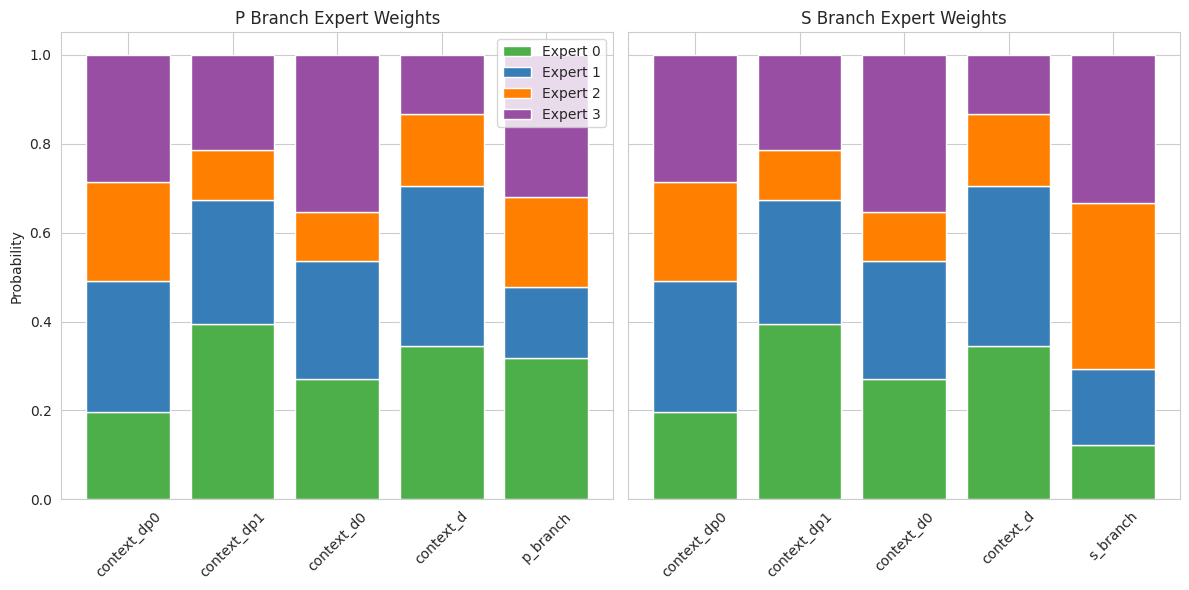

In [8]:
import matplotlib.pyplot as plt

# 筛选 P 和 S 分支的数据
df_p_plot = df_instance[df_instance['branch'] == 'P'].set_index('layer').drop(columns='branch')
df_s_plot = df_instance[df_instance['branch'] == 'S'].set_index('layer').drop(columns='branch')

# 确保层顺序一致
moe_layers = ['context_dp0', 'context_dp1', 'context_d0', 'context_d', 'p_branch']
df_p_plot = df_p_plot.loc[moe_layers]
df_s_plot = df_s_plot.loc[[l.replace('p_branch', 's_branch') if 'p_branch' in l else l for l in moe_layers]]


# 绘图
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
colors = ['#4daf4a', '#377eb8', '#ff7f00', '#984ea3']
x = range(len(moe_layers))

# 绘制 P 分支
bottom = np.zeros(len(moe_layers))
for i in range(4):
    axes[0].bar(x, df_p_plot[f'expert_{i}'], bottom=bottom, color=colors[i], label=f'Expert {i}')
    bottom += df_p_plot[f'expert_{i}'].values
axes[0].set_xticks(x)
axes[0].set_xticklabels(moe_layers, rotation=45)
axes[0].set_title('P Branch Expert Weights')
axes[0].set_ylabel('Probability')
axes[0].legend()

# 绘制 S 分支
bottom = np.zeros(len(moe_layers))
for i in range(4):
    axes[1].bar(x, df_s_plot[f'expert_{i}'], bottom=bottom, color=colors[i], label=f'Expert {i}')
    bottom += df_s_plot[f'expert_{i}'].values
axes[1].set_xticks(x)
axes[1].set_xticklabels([l.replace('p_branch', 's_branch') for l in moe_layers], rotation=45)
axes[1].set_title('S Branch Expert Weights')

plt.tight_layout()
plt.show()


## DiTing

### Weights

In [9]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]="2"

from Auxiliary import (
    ResCNNBlock, BiLSTMBlock, LayerNormalization, FeedForward,
    CustomLSTM, ActivationLSTMCell, TimeMoeSparseExpertsLayer,
    TimeMoeConfig, load_balancing_loss_func,TimeMoeAttention
)
from model_moe_gpt_PS2_CPU import MoEGlobalContextModule,MultiScaleFeatureExtractor,CNNResBlockStack,StackedBiLSTM,CRNNModule,CustomLSTM,TCNModule,PS1PickingBranch,PS2PickingBranch



import sys
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
from model_moe_gpt_PS2_CPU import IMG1

def normalize_data(data, mode='std'):
    data -= np.mean(data, axis=1, keepdims=True)
    if mode == 'std':
        std_val = np.std(data, axis=1, keepdims=True)
        std_val[std_val == 0] = 1.0
        data /= std_val
    elif mode == 'max':
        max_val = np.max(np.abs(data), axis=1, keepdims=True)
        max_val[max_val == 0] = 1.0
        data /= max_val
    else:
        raise ValueError(f"Unsupported norm_mode: {mode}")
    return data

def bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    filtered = np.zeros_like(data)
    for ch in range(data.shape[0]):
        filtered[ch] = filtfilt(b, a, data[ch])
    return filtered

def collect_expert_weights(model, input_data):
    model.eval()
    p_weights = {}  # {layer_name: expert_weights}
    s_weights = {}  # {layer_name: expert_weights}
    with torch.no_grad():
        # Process with MultiScaleFeatureExtractor
        feat = model.feature_extractor(input_data.permute(0, 2, 1))  # [batch, 64, seq_len]
        print(f"MultiScaleFeatureExtractor output shape: {feat.shape}")

        # Temporary dimension reduction for all MoE layers
        feat_reduced = feat.permute(0, 2, 1)  # [batch, seq_len, 64]
        weight = torch.nn.Parameter(torch.randn(16,64)).to(feat.device)  # [in_features=64, out_features=16]
        feat_reduced = torch.nn.functional.linear(feat_reduced, weight)  # [batch, seq_len, 16]
        feat_reduced = feat_reduced.permute(0, 2, 1)  # [batch, 16, seq_len]
        print(f"Reduced feat shape for all MoE layers: {feat_reduced.shape}")

        # Process context_dp0
        try:
            moe_out, moe_weights, router_logits = model.context_dp0(feat)
            print(f"context_dp0 router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_dp0'] = weights
            s_weights['context_dp0'] = weights
            print(f"context_dp0 expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_dp0: {str(e)}")

        # Process context_dp1
        try:
            moe_out, moe_weights, router_logits = model.context_dp1(feat)
            print(f"context_dp1 router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_dp1'] = weights
            s_weights['context_dp1'] = weights
            print(f"context_dp1 expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_dp1: {str(e)}")

        # Process context_d0
        try:
            moe_out, moe_weights, router_logits = model.context_d0(feat_reduced)
            print(f"context_d0 router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_d0'] = weights
            s_weights['context_d0'] = weights
            print(f"context_d0 expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_d0: {str(e)}")

        # Process context_d
        try:
            moe_out, moe_weights, router_logits = model.context_d(feat_reduced)
            print(f"context_d router_logits shape: {router_logits.shape}")
            router_probs = torch.softmax(router_logits, dim=-1)[0].cpu().numpy()
            weights = router_probs.mean(axis=0) if router_probs.ndim == 2 else router_probs
            p_weights['context_d'] = weights
            s_weights['context_d'] = weights
            print(f"context_d expert weights: {weights}")
        except Exception as e:
            print(f"Error processing context_d: {str(e)}")

        # Process p_branch
        try:
            moe_out_p, moe_weights_p, p_router_logits = model.p_branch.attn_branch(feat_reduced)
            print(f"p_branch router_logits shape: {p_router_logits.shape}")
            p_router_probs = torch.softmax(p_router_logits, dim=-1)[0].cpu().numpy()
            p_weights['p_branch'] = p_router_probs.mean(axis=0) if p_router_probs.ndim == 2 else p_router_probs
            print(f"p_branch expert weights: {p_weights['p_branch']}")
        except Exception as e:
            print(f"Error processing p_branch: {str(e)}")

        # Process s_branch
        try:
            moe_out_s, moe_weights_s, s_router_logits = model.s_branch.attn_branch(feat_reduced)
            print(f"s_branch router_logits shape: {s_router_logits.shape}")
            s_router_probs = torch.softmax(s_router_logits, dim=-1)[0].cpu().numpy()
            s_weights['s_branch'] = s_router_probs.mean(axis=0) if s_router_probs.ndim == 2 else s_router_probs
            print(f"s_branch expert weights: {s_weights['s_branch']}")
        except Exception as e:
            print(f"Error processing s_branch: {str(e)}")

    return p_weights, s_weights

def visualize_expert_weights(p_weights, s_weights, input_signal, hdf5_path, trace_name, num_experts=4):
    with h5py.File(hdf5_path, 'r') as f:
        dataset = f['data'].get(trace_name)
        p_arrival = dataset.attrs['p_arrival_sample'] / 100
        s_arrival = dataset.attrs['s_arrival_sample'] / 100

    layers = list(set(p_weights.keys()) | set(s_weights.keys()))
    x = np.arange(num_experts)
    width = 0.15
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'][:len(layers)]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12), sharex=False)
    signal_time = np.linspace(0, input_signal.shape[1] / 100, input_signal.shape[1])
    ax1.plot(signal_time, input_signal[0].T.cpu().numpy()[0], label='Z')
    ax1.axvline(p_arrival, color='r', linestyle='--', label='P Arrival')
    ax1.axvline(s_arrival, color='g', linestyle='--', label='S Arrival')
    ax1.set_xlabel("Time (s)")
    ax1.set_ylabel("Amplitude")
    ax1.legend()
    ax1.set_title("Input Seismic Signal")

    for i, layer in enumerate(layers):
        p_vals = p_weights.get(layer, np.zeros(num_experts))
        s_vals = s_weights.get(layer, np.zeros(num_experts))
        offset = i * width - (len(layers) - 1) * width / 2
        ax2.bar(x + offset - width/2, p_vals, width/2, label=f"{layer} (P)", color=colors[i], alpha=0.6)
        ax2.bar(x + offset + width/2, s_vals, width/2, label=f"{layer} (S)", color=colors[i], alpha=0.9)

    ax2.set_xlabel("Expert Index")
    ax2.set_ylabel("Mean Routing Probability")
    ax2.set_title("Expert Utilization Across Layers (P and S Branches)")
    ax2.set_xticks(x)
    ax2.set_xticklabels([f"Expert {i+1}" for i in range(num_experts)])
    ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    ax2.grid(True, axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

# Modified IMG1 class with corrected in_dim
class IMG1(nn.Module):
    def __init__(self,
                 in_channels=3,
                 in_samples=6000,
                 drop_rate=0.1,
                 original_compatible=False,
                 use_moe=True,
                 num_experts=4,
                 num_experts_per_tok=4,
                 intermediate_size=256,
                 hidden_act="gelu",
                 router_aux_loss_factor=0.01,
                 **kwargs):
        super().__init__()
        self.in_channels = in_channels
        self.in_samples = in_samples
        self.drop_rate = drop_rate
        self.original_compatible = original_compatible

        self.filters = [8, 16, 16, 32, 32, 64, 64]
        self.kernel_sizes = [11, 9, 7, 7, 5, 5, 3]
        self.res_cnn_kernels = [3, 3, 3, 3, 2, 3, 2]

        self.feature_extractor = MultiScaleFeatureExtractor(
            in_channels=self.in_channels,
            filters=self.filters,
            kernel_sizes=self.kernel_sizes,
            in_samples=self.in_samples
        )
        moe_cfg_64 = TimeMoeConfig(
            hidden_size=64,
            num_experts=num_experts,
            num_experts_per_tok=num_experts_per_tok,
            intermediate_size=4*64,
            hidden_act=hidden_act,
            router_aux_loss_factor=router_aux_loss_factor
        )
        self.context_dp0 = MoEGlobalContextModule(64, drop_rate, eps=1e-5, moe_config=moe_cfg_64)
        self.context_dp1 = MoEGlobalContextModule(64, drop_rate, eps=1e-5, moe_config=moe_cfg_64)

        self.cnn_res_stack = CNNResBlockStack(
            kernel_list=self.res_cnn_kernels,
            out_channels=self.filters[-1],
            dropout_rate=self.drop_rate
        )
        self.bi_lstm = StackedBiLSTM(
            num_blocks=3,
            input_dim=64,
            dropout_rate=self.drop_rate,
            original_compatible=original_compatible
        )
        moe_cfg_16 = TimeMoeConfig(
            hidden_size=16,
            num_experts=num_experts,
            num_experts_per_tok=num_experts_per_tok,
            intermediate_size=4*16,
            hidden_act=hidden_act,
            router_aux_loss_factor=router_aux_loss_factor
        )
        self.context_d0 = MoEGlobalContextModule(16, drop_rate, eps=1e-5, moe_config=moe_cfg_16)
        self.context_d = MoEGlobalContextModule(16, drop_rate, eps=1e-5, moe_config=moe_cfg_16)

        self.p_branch = PS2PickingBranch(
            in_dim=16,  # Corrected to match bi_lstm output
            out_samples=self.in_samples,
            drop_rate=self.drop_rate,
            filters=self.filters,
            kernel_sizes=self.kernel_sizes,
            original_compatible=original_compatible,
            moe_config=moe_cfg_16
        )
        self.s_branch = PS2PickingBranch(
            in_dim=16,  # Corrected to match bi_lstm output
            out_samples=self.in_samples,
            drop_rate=self.drop_rate,
            filters=self.filters,
            kernel_sizes=self.kernel_sizes,
            original_compatible=original_compatible,
            moe_config=moe_cfg_16
        )

    def forward(self, x, logits=False):
        x = x.permute(0, 2, 1)
        feat = self.feature_extractor(x)
        feat, _, router_dp0 = self.context_dp0(feat)
        feat, _, router_dp1 = self.context_dp1(feat)
        feat = self.cnn_res_stack(feat)
        feat = self.bi_lstm(feat)
        feat, _, router_d0 = self.context_d0(feat)
        feat, _, router_d = self.context_d(feat)

        p_pred = self.p_branch(feat, logits=logits)
        s_pred = self.s_branch(feat, logits=logits)

        router_list = []
        if router_dp0 is not None: router_list.append(router_dp0)
        if router_dp1 is not None: router_list.append(router_dp1)
        if router_d0 is not None: router_list.append(router_d0)
        if router_d is not None: router_list.append(router_d)

        balance_loss = torch.tensor(0.0, device=x.device)
        if router_list:
            balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))

        return (p_pred, s_pred), balance_loss

# Usage example
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

hdf5_path="/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/谛听1.0-50HZ/Diting50hz/processed/DiTing330km_part_26_processed.hdf5"
p_thresh=0.1,
s_thresh=0.1
trace_name= '689168.0903_EV'
def normalize_data1(data, mode='std'):
        data -= np.mean(data, axis=1, keepdims=True)

        if mode == 'std':
            std_val = np.std(data, axis=1, keepdims=True)
            std_val[std_val == 0] = 1.0
            data /= std_val
        elif mode == 'max':
            max_val = np.max(np.abs(data), axis=1, keepdims=True)
            max_val[max_val == 0] = 1.0
            data /= max_val
        else:
            raise ValueError(f"Unsupported norm_mode: {mode}")
        return data

def normalize_data2(data, mode='max'):
    data -= np.mean(data, axis=0, keepdims=True)
    if mode == 'max':
        max_data = np.max(data, axis=0, keepdims=True)
        assert (max_data.shape[-1] == data.shape[-1])
        max_data[max_data == 0] = 1
        data /= max_data

    elif mode == 'std':
        std_data = np.std(data, axis=0, keepdims=True)
        assert (std_data.shape[-1] == data.shape[-1])
        std_data[std_data == 0] = 1
        data /= std_data
    return data


with h5py.File(hdf5_path, 'r') as f:
    if 'data' not in f:
        raise KeyError("HDF5文件中缺少'data'组")
    dataset = f['data'].get(trace_name)
    normalized = dataset[:].astype(np.float32).T  # shape: (3, n_samples)
# normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
# 滤波：1-45Hz 带通滤波
normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
#
# # 标准化
normalized = normalize_data1(normalized, 'std')
data=torch.from_numpy(normalized.T).unsqueeze(0)
input_signal = data.clone().to(device)

# Load model
model = IMG1(num_experts=4, num_experts_per_tok=4).to(device)

# Collect and visualize expert weights
p_weights, s_weights = collect_expert_weights(model, input_signal)
import pandas as pd
# 将 expert 权重转换为 DataFrame
def weights_to_dataframe(weights_dict, label):
    df = pd.DataFrame.from_dict(weights_dict, orient='index')
    df.columns = [f'expert_{i}' for i in range(df.shape[1])]
    df.index.name = 'layer'
    df['branch'] = label
    return df.reset_index()

# 转换为 DataFrame
df_p = weights_to_dataframe(p_weights, 'P')
df_s = weights_to_dataframe(s_weights, 'S')

# 合并两个 DataFrame
df_diting= pd.concat([df_p, df_s], ignore_index=True)

# 打印 DataFrame 结果

df_diting.to_csv('/home/yuan/code/SeisMoE/data/expert_weights/expert_weights_diting.csv', index=False)

df_diting

# visualize_expert_weights(p_weights, s_weights, input_signal, hdf5_path, trace_name, num_experts=4)

MultiScaleFeatureExtractor output shape: torch.Size([1, 64, 47])
Reduced feat shape for all MoE layers: torch.Size([1, 16, 47])
context_dp0 router_logits shape: torch.Size([47, 4])
context_dp0 expert weights: [0.09921945 0.24030475 0.47824392 0.18223184]
context_dp1 router_logits shape: torch.Size([47, 4])
context_dp1 expert weights: [0.36561266 0.2788016  0.15795557 0.1976302 ]
context_d0 router_logits shape: torch.Size([47, 4])
context_d0 expert weights: [0.16574447 0.3442257  0.16047673 0.3295531 ]
context_d router_logits shape: torch.Size([47, 4])
context_d expert weights: [0.3961857  0.11307151 0.12764178 0.36310104]
p_branch router_logits shape: torch.Size([47, 4])
p_branch expert weights: [0.09242708 0.14904515 0.35387054 0.40465719]
s_branch router_logits shape: torch.Size([47, 4])
s_branch expert weights: [0.14985402 0.2874464  0.1124498  0.45024973]


,layer,expert_0,expert_1,expert_2,expert_3,branch
0,context_dp0,0.099219,0.240305,0.478244,0.182232,P
1,context_dp1,0.365613,0.278802,0.157956,0.197630,P
2,context_d0,0.165744,0.344226,0.160477,0.329553,P
3,context_d,0.396186,0.113072,0.127642,0.363101,P
4,p_branch,0.092427,0.149045,0.353871,0.404657,P
5,context_dp0,0.099219,0.240305,0.478244,0.182232,S
6,context_dp1,0.365613,0.278802,0.157956,0.197630,S
7,context_d0,0.165744,0.344226,0.160477,0.329553,S
8,context_d,0.396186,0.113072,0.127642,0.363101,S
9,s_branch,0.149854,0.287446,0.112450,0.450250,S


### Draw

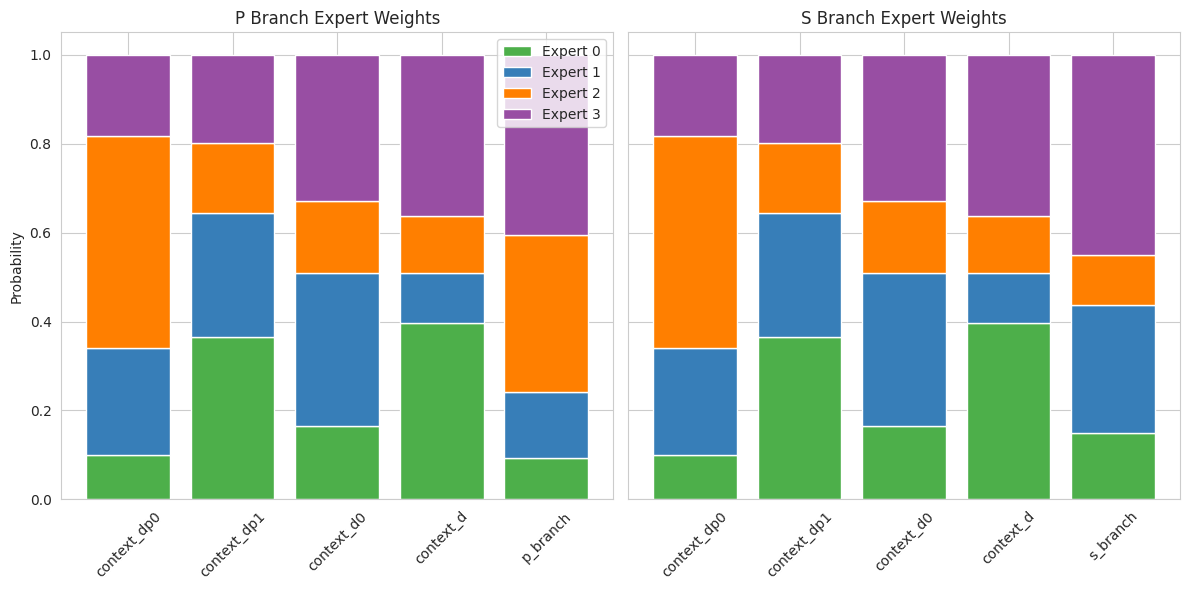

In [10]:
import matplotlib.pyplot as plt

# 筛选 P 和 S 分支的数据
df_p_plot = df_diting[df_diting['branch'] == 'P'].set_index('layer').drop(columns='branch')
df_s_plot = df_diting[df_diting['branch'] == 'S'].set_index('layer').drop(columns='branch')

# 确保层顺序一致
moe_layers = ['context_dp0', 'context_dp1', 'context_d0', 'context_d', 'p_branch']
df_p_plot = df_p_plot.loc[moe_layers]
df_s_plot = df_s_plot.loc[[l.replace('p_branch', 's_branch') if 'p_branch' in l else l for l in moe_layers]]


# 绘图
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
colors = ['#4daf4a', '#377eb8', '#ff7f00', '#984ea3']
x = range(len(moe_layers))

# 绘制 P 分支
bottom = np.zeros(len(moe_layers))
for i in range(4):
    axes[0].bar(x, df_p_plot[f'expert_{i}'], bottom=bottom, color=colors[i], label=f'Expert {i}')
    bottom += df_p_plot[f'expert_{i}'].values
axes[0].set_xticks(x)
axes[0].set_xticklabels(moe_layers, rotation=45)
axes[0].set_title('P Branch Expert Weights')
axes[0].set_ylabel('Probability')
axes[0].legend()

# 绘制 S 分支
bottom = np.zeros(len(moe_layers))
for i in range(4):
    axes[1].bar(x, df_s_plot[f'expert_{i}'], bottom=bottom, color=colors[i], label=f'Expert {i}')
    bottom += df_s_plot[f'expert_{i}'].values
axes[1].set_xticks(x)
axes[1].set_xticklabels([l.replace('p_branch', 's_branch') for l in moe_layers], rotation=45)
axes[1].set_title('S Branch Expert Weights')

plt.tight_layout()
plt.show()


#  Draw All

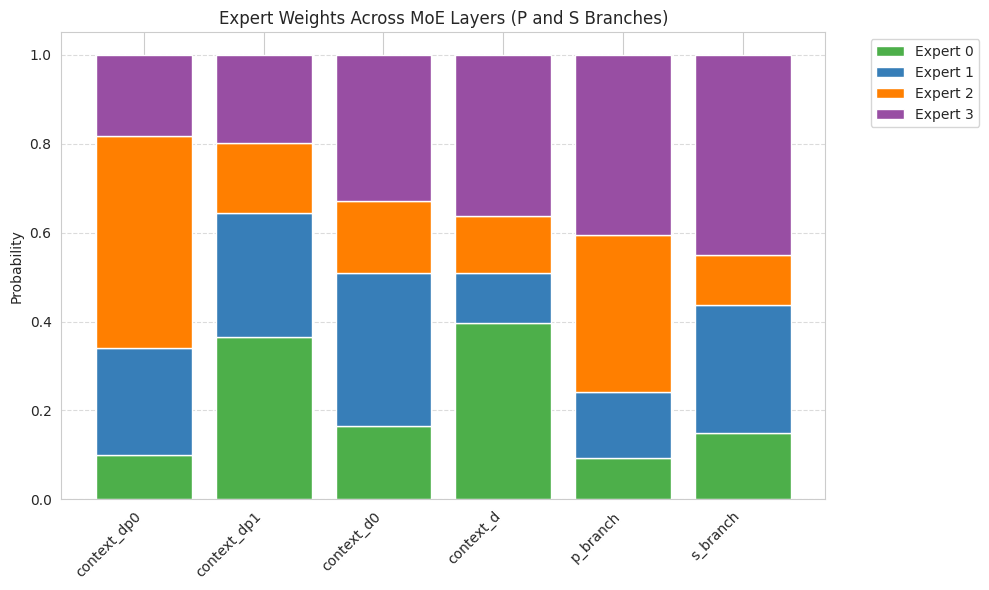

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# 假设 df_diting 已定义，筛选 P 和 S 分支数据
df_p_plot = df_diting[df_diting['branch'] == 'P'].set_index('layer').drop(columns='branch')
df_s_plot = df_diting[df_diting['branch'] == 'S'].set_index('layer').drop(columns='branch')

# 定义层顺序
moe_layers = ['context_dp0', 'context_dp1', 'context_d0', 'context_d', 'p_branch', 's_branch']

# 准备绘图数据
# 前 4 个层从 P 分支取（P 和 S 相同），最后两个分别从 p_branch 和 s_branch
plot_data = []
for layer in moe_layers:
    if layer in ['context_dp0', 'context_dp1', 'context_d0', 'context_d']:
        # 共享层，从 P 分支取
        plot_data.append(df_p_plot.loc[layer][['expert_0', 'expert_1', 'expert_2', 'expert_3']].values)
    elif layer == 'p_branch':
        plot_data.append(df_p_plot.loc['p_branch'][['expert_0', 'expert_1', 'expert_2', 'expert_3']].values)
    elif layer == 's_branch':
        plot_data.append(df_s_plot.loc['s_branch'][['expert_0', 'expert_1', 'expert_2', 'expert_3']].values)

# 转换为 numpy 数组，形状 [6, 4]（6 个层，4 个专家）
plot_data = np.array(plot_data)

# 绘图
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#4daf4a', '#377eb8', '#ff7f00', '#984ea3']  # 绿、蓝、橙、紫
x = range(len(moe_layers))

# 堆叠柱状图
bottom = np.zeros(len(moe_layers))
for i in range(4):
    ax.bar(x, plot_data[:, i], bottom=bottom, color=colors[i], label=f'Expert {i}')
    bottom += plot_data[:, i]

# 设置 X 轴和标签
ax.set_xticks(x)
ax.set_xticklabels(moe_layers, rotation=45, ha='right')
ax.set_ylabel('Probability')
ax.set_title('Expert Weights Across MoE Layers (P and S Branches)')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
ax.grid(True, axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import scienceplots
from matplotlib.ticker import PercentFormatter

# 设置全局字体参数（强制锁定所有字体大小）
size=25
plt.rcParams.update({
    'font.size': size,  # 基础字体大小
    'axes.titlesize': size,  # 子图标题
    'axes.labelsize': size,  # 轴标签
    'xtick.labelsize': size,  # x轴刻度
    'ytick.labelsize': size,  # y轴刻度
    'legend.fontsize': size,  # 图例
})

# 应用 scienceplots 风格（锁定IEEE格式）
plt.style.use(['science', 'grid', 'ieee'])

# 定义绘图函数（字体大小由全局参数控制）
def plot_expert_weights(ax, df, title):
    df_p = df[df['branch'] == 'P'].set_index('layer').drop(columns='branch')
    df_s = df[df['branch'] == 'S'].set_index('layer').drop(columns='branch')

    moe_layers = ['context_dp0', 'context_dp1', 'context_d0', 'context_d', 'p_branch', 's_branch']
    layer_names = ['share1', 'share2', 'share3', 'share4', 'P ', 'S ']

    plot_data = []
    for layer in moe_layers:
        if layer in ['context_dp0', 'context_dp1', 'context_d0', 'context_d']:
            plot_data.append(df_p.loc[layer][['expert_0', 'expert_1', 'expert_2', 'expert_3']].values)
        elif layer == 'p_branch':
            plot_data.append(df_p.loc['p_branch'][['expert_0', 'expert_1', 'expert_2', 'expert_3']].values)
        elif layer == 's_branch':
            plot_data.append(df_s.loc['s_branch'][['expert_0', 'expert_1', 'expert_2', 'expert_3']].values)
    plot_data = np.array(plot_data)

    colors = ['#1B450E', '#85B243', '#CEE55D', '#FBE59E']
    x = range(len(layer_names))

    bottom = np.zeros(len(layer_names))
    for i in range(4):
        ax.bar(x, plot_data[:, i], bottom=bottom, color=colors[i], label=f'Expert {i+1}', width=0.6)
        bottom += plot_data[:, i]

    ax.set_xticks(x)
    ax.set_xticklabels(layer_names)  # 保持旋转对齐
    ax.set_xlabel('MoE Layer')
    ax.set_ylabel('Probability')
    ax.set_title(title)
    ax.grid(True, axis='y', linestyle=':', alpha=0.5)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_ylim(0, 1.0)

# 创建子图（调整画布比例适应大字体）
fig, axs = plt.subplots(2, 2, figsize=(16, 14))  # 增大画布尺寸

# 绘制子图
plot_expert_weights(axs[0, 0], df_stead, 'Stead')
plot_expert_weights(axs[0, 1], df_txed, 'Txed')
plot_expert_weights(axs[1, 0], df_instance, 'Instance')
plot_expert_weights(axs[1, 1], df_diting, 'Diting')

# 统一图例（底部居中，增加与子图的间距）
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels,
           loc='lower center',
           bbox_to_anchor=(0.5, -0.05),  # 向下移动图例
           ncol=4,
           frameon=True,
           borderaxespad=1.0)  # 增加边框间距

# 调整布局（扩大底部边距）
plt.tight_layout()
plt.subplots_adjust(bottom=0.10, hspace=0.3, wspace=0.2)  # 增加子图间距

# 输出矢量图
plt.savefig('moe_experts_2x2.pdf', dpi=600, bbox_inches='tight')
plt.savefig('moe_experts_2x2.svg', dpi=600, bbox_inches='tight')
plt.show()

In [48]:
combined_df = pd.concat([df_stead, df_txed, df_instance, df_diting],
                        axis=0, keys=['stead', 'txed', 'instance', 'diting'])
combined_df

layer  expert_0  expert_1  expert_2  expert_3 branch
stead    0  context_dp0  0.122429  0.099399  0.657028  0.121144      P
         1  context_dp1  0.338763  0.243110  0.211247  0.206880      P
         2   context_d0  0.247434  0.195292  0.292285  0.264989      P
         3    context_d  0.162701  0.113818  0.168005  0.555476      P
         4     p_branch  0.133848  0.245959  0.541893  0.078301      P
         5  context_dp0  0.122429  0.099399  0.657028  0.121144      S
         6  context_dp1  0.338763  0.243110  0.211247  0.206880      S
         7   context_d0  0.247434  0.195292  0.292285  0.264989      S
         8    context_d  0.162701  0.113818  0.168005  0.555476      S
         9     s_branch  0.084869  0.099838  0.625312  0.189981      S
txed     0  context_dp0  0.269489  0.285356  0.326996  0.118159      P
         1  context_dp1  0.252250  0.189386  0.285128  0.273235      P
         2   context_d0  0.122334  0.071257  0.292648  0.513761      P
         3    context_d  0.297715  0.322304  0.220153  0.159829      P
         4     p_branch  0.345054  0.128538  0.284287  0.242121      P
         5  context_dp0  0.269489  0.285356  0.326996  0.118159      S
         6  context_dp1  0.252250  0.189386  0.285128  0.273235      S
         7   context_d0  0.122334  0.071257  0.292648  0.513761      S
         8    context_d  0.297715  0.322304  0.220153  0.159829      S
         9     s_branch  0.193764  0.352298  0.097971  0.355967      S
instance 0  context_dp0  0.196076  0.295446  0.222365  0.286113      P
         1  context_dp1  0.395481  0.278031  0.111116  0.215372      P
         2   context_d0  0.271461  0.264954  0.109871  0.353714      P
         3    context_d  0.345154  0.359281  0.162362  0.133203      P
         4     p_branch  0.318496  0.157964  0.202703  0.320836      P
         5  context_dp0  0.196076  0.295446  0.222365  0.286113      S
         6  context_dp1  0.395481  0.278031  0.111116  0.215372      S
         7   context_d0  0.271461  0.264954  0.109871  0.353714      S
         8    context_d  0.345154  0.359281  0.162362  0.133203      S
         9     s_branch  0.122884  0.170367  0.372767  0.333982      S
diting   0  context_dp0  0.099219  0.240305  0.478244  0.182232      P
         1  context_dp1  0.365613  0.278802  0.157956  0.197630      P
         2   context_d0  0.165744  0.344226  0.160477  0.329553      P
         3    context_d  0.396186  0.113072  0.127642  0.363101      P
         4     p_branch  0.092427  0.149045  0.353871  0.404657      P
         5  context_dp0  0.099219  0.240305  0.478244  0.182232      S
         6  context_dp1  0.365613  0.278802  0.157956  0.197630      S
         7   context_d0  0.165744  0.344226  0.160477  0.329553      S
         8    context_d  0.396186  0.113072  0.127642  0.363101      S
         9     s_branch  0.149854  0.287446  0.112450  0.450250      S

|  |  | layer | expert\_0 | expert\_1 | expert\_2 | expert\_3 | branch |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| stead | 0 | context\_dp0 | 0.122429 | 0.099399 | 0.657028 | 0.121144 | P |
|  | 1 | context\_dp1 | 0.338763 | 0.243110 | 0.211247 | 0.206880 | P |
|  | 2 | context\_d0 | 0.247434 | 0.195292 | 0.292285 | 0.264989 | P |
|  | 3 | context\_d | 0.162701 | 0.113818 | 0.168005 | 0.555476 | P |
|  | 4 | p\_branch | 0.133848 | 0.245959 | 0.541893 | 0.078301 | P |
|  | 5 | context\_dp0 | 0.122429 | 0.099399 | 0.657028 | 0.121144 | S |
|  | 6 | context\_dp1 | 0.338763 | 0.243110 | 0.211247 | 0.206880 | S |
|  | 7 | context\_d0 | 0.247434 | 0.195292 | 0.292285 | 0.264989 | S |
|  | 8 | context\_d | 0.162701 | 0.113818 | 0.168005 | 0.555476 | S |
|  | 9 | s\_branch | 0.084869 | 0.099838 | 0.625312 | 0.189981 | S |
| txed | 0 | context\_dp0 | 0.269489 | 0.285356 | 0.326996 | 0.118159 | P |
|  | 1 | context\_dp1 | 0.252250 | 0.189386 | 0.285128 | 0.273235 | P |
|  | 2 | context\_d0 | 0.122334 | 0.071257 | 0.292648 | 0.513761 | P |
|  | 3 | context\_d | 0.297715 | 0.322304 | 0.220153 | 0.159829 | P |
|  | 4 | p\_branch | 0.345054 | 0.128538 | 0.284287 | 0.242121 | P |
|  | 5 | context\_dp0 | 0.269489 | 0.285356 | 0.326996 | 0.118159 | S |
|  | 6 | context\_dp1 | 0.252250 | 0.189386 | 0.285128 | 0.273235 | S |
|  | 7 | context\_d0 | 0.122334 | 0.071257 | 0.292648 | 0.513761 | S |
|  | 8 | context\_d | 0.297715 | 0.322304 | 0.220153 | 0.159829 | S |
|  | 9 | s\_branch | 0.193764 | 0.352298 | 0.097971 | 0.355967 | S |
| instance | 0 | context\_dp0 | 0.196076 | 0.295446 | 0.222365 | 0.286113 | P |
|  | 1 | context\_dp1 | 0.395481 | 0.278031 | 0.111116 | 0.215372 | P |
|  | 2 | context\_d0 | 0.271461 | 0.264954 | 0.109871 | 0.353714 | P |
|  | 3 | context\_d | 0.345154 | 0.359281 | 0.162362 | 0.133203 | P |
|  | 4 | p\_branch | 0.318496 | 0.157964 | 0.202703 | 0.320836 | P |
|  | 5 | context\_dp0 | 0.196076 | 0.295446 | 0.222365 | 0.286113 | S |
|  | 6 | context\_dp1 | 0.395481 | 0.278031 | 0.111116 | 0.215372 | S |
|  | 7 | context\_d0 | 0.271461 | 0.264954 | 0.109871 | 0.353714 | S |
|  | 8 | context\_d | 0.345154 | 0.359281 | 0.162362 | 0.133203 | S |
|  | 9 | s\_branch | 0.122884 | 0.170367 | 0.372767 | 0.333982 | S |
| diting | 0 | context\_dp0 | 0.099219 | 0.240305 | 0.478244 | 0.182232 | P |
|  | 1 | context\_dp1 | 0.365613 | 0.278802 | 0.157956 | 0.197630 | P |
|  | 2 | context\_d0 | 0.165744 | 0.344226 | 0.160477 | 0.329553 | P |
|  | 3 | context\_d | 0.396186 | 0.113072 | 0.127642 | 0.363101 | P |
|  | 4 | p\_branch | 0.092427 | 0.149045 | 0.353871 | 0.404657 | P |
|  | 5 | context\_dp0 | 0.099219 | 0.240305 | 0.478244 | 0.182232 | S |
|  | 6 | context\_dp1 | 0.365613 | 0.278802 | 0.157956 | 0.197630 | S |
|  | 7 | context\_d0 | 0.165744 | 0.344226 | 0.160477 | 0.329553 | S |
|  | 8 | context\_d | 0.396186 | 0.113072 | 0.127642 | 0.363101 | S |
|  | 9 | s\_branch | 0.149854 | 0.287446 | 0.112450 | 0.450250 | S |


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scienceplots
from matplotlib.ticker import PercentFormatter

df_stead=pd.read_csv(r'/home/yuan/code/SeisMoE/data/expert_weights/expert_weights_stead.csv')
df_txed=pd.read_csv(r'/home/yuan/code/SeisMoE/data/expert_weights/expert_weights_txed.csv')
df_instance=pd.read_csv(r'/home/yuan/code/SeisMoE/data/expert_weights/expert_weights_instance.csv')
df_diting=pd.read_csv(r'/home/yuan/code/SeisMoE/data/expert_weights/expert_weights_diting.csv')



# 设置全局字体参数
size = 25
plt.rcParams.update({
    'font.size': size,
    'axes.titlesize': size,
    'axes.labelsize': size,
    'xtick.labelsize': size,
    'ytick.labelsize': size,
    'legend.fontsize': size,
})

# 应用 scienceplots 风格
plt.style.use(['science', 'grid', 'ieee'])

def plot_expert_weights(ax, df, title):
    df_p = df[df['branch'] == 'P'].set_index('layer').drop(columns='branch')
    df_s = df[df['branch'] == 'S'].set_index('layer').drop(columns='branch')

    moe_layers = ['context_dp0', 'context_dp1', 'context_d0', 'context_d', 'p_branch', 's_branch']
    layer_names = ['share1', 'share2', 'share3', 'share4', 'P ', 'S ']

    plot_data = []
    for layer in moe_layers:
        if layer in ['context_dp0', 'context_dp1', 'context_d0', 'context_d']:
            plot_data.append(df_p.loc[layer][['expert_0', 'expert_1', 'expert_2', 'expert_3']].values)
        elif layer == 'p_branch':
            plot_data.append(df_p.loc['p_branch'][['expert_0', 'expert_1', 'expert_2', 'expert_3']].values)
        elif layer == 's_branch':
            plot_data.append(df_s.loc['s_branch'][['expert_0', 'expert_1', 'expert_2', 'expert_3']].values)
    plot_data = np.array(plot_data)

    colors = ['#1B450E', '#85B243', '#CEE55D', '#FBE59E']
    x = range(len(layer_names))

    bottom = np.zeros(len(layer_names))
    for i in range(4):
        bars = ax.bar(x, plot_data[:, i], bottom=bottom, color=colors[i], label=f'Expert {i+1}', width=0.6)

        # 添加数值标签
        for j, (bar, val) in enumerate(zip(bars, plot_data[:, i])):
            if val > 0.01:  # 只显示大于1%的值
                ax.text(bar.get_x() + bar.get_width()/2,
                        bottom[j] + val/2,
                        f'{val:.2f}',  # 显示两位小数
                        ha='center', va='center',
                        color='black', fontsize=size*0.8)

        bottom += plot_data[:, i]

    ax.set_xticks(x)
    ax.set_xticklabels(layer_names)
    ax.set_xlabel('MoE Layer')
    ax.set_ylabel('Probability')
    ax.set_title(title)
    ax.grid(True, axis='y', linestyle=':', alpha=0.5)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_ylim(0, 1.0)

# 创建子图
fig, axs = plt.subplots(2, 2, figsize=(16, 14))

# 绘制子图
plot_expert_weights(axs[0, 0], df_stead, 'Stead')
plot_expert_weights(axs[0, 1], df_txed, 'Txed')
plot_expert_weights(axs[1, 0], df_instance, 'Instance')
plot_expert_weights(axs[1, 1], df_diting, 'Diting')

# 统一图例
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels,
           loc='lower center',
           bbox_to_anchor=(0.5, -0.05),
           ncol=4,
           frameon=True,
           borderaxespad=1.0)

# 调整布局
plt.tight_layout()
plt.subplots_adjust(bottom=0.15, hspace=0.3, wspace=0.2)


# 输出图像
plt.savefig('moe_experts_2x21.pdf', dpi=600, bbox_inches='tight')
plt.savefig('moe_experts_2x21.svg', dpi=600, bbox_inches='tight')
plt.show()